# 021 Final classifiers: one CLAM-MB per label set

**Overview.** One CLAM-MB is trained for each of three coarser label sets derived from the seven BRACS classes, and each is evaluated once on the official Testing set. The architecture, the optimiser and the regularisation are the setting selected by cross-validation in `02_vectors_to_classifier.ipynb`; no choice is made here, so the Testing set is used for reporting only.

```mermaid
flowchart TD
    subgraph IN["Inputs"]
        FEAT[("FEATURES_DIR/UNI2-h/<br/>one .pt file per slide (from 01)")]
        LAB[("labels/BRACS.xlsx<br/>class, patient, official set")]
    end

    subgraph S3["3. Data"]
        D1["3.1 build_slide_table + load_bags"]
        D2["3.2 make_holdout_split<br/>fit / early stopping (patient-grouped)"]
        D3["3.3 relabel_table<br/>three label sets"]
    end

    subgraph S4["4. Training (one CLAM-MB per label set)"]
        T1["train_final<br/>constants fixed from 02"]
        T2["plot_training_curves"]
    end

    subgraph S5["5. Evaluation (Testing set, used once)"]
        E1["predict_testing"]
        E2["class_views + bootstrap_views<br/>accuracy, F1, recall, precision,<br/>sensitivity, specificity, AUROC"]
        E3["plot_final_results<br/>confusion matrix + ROC"]
    end

    OUT[("classifier/final/label set/<br/>classifier_model_date-time.pt")]

    FEAT --> D1
    LAB --> D1
    D1 --> D2
    D2 --> D3
    D3 --> T1
    T1 --> T2
    T1 --> E1
    E1 --> E2
    E1 --> E3
    T1 --> OUT
```

## 1. Setup

The environment is recorded so the run can be reproduced.

In [1]:
# STEP 1: Import general-purpose third-party libraries
import sys
import matplotlib
import numpy as np
import pandas as pd
import sklearn
import torch

# STEP 2: Print library versions for reproducibility
print('System Version:', sys.version)
print('PyTorch version:', torch.__version__)
print('Scikit-learn version:', sklearn.__version__)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('Matplotlib version:', matplotlib.__version__)

System Version: 3.14.7 (main, Aug 10 2026, 07:46:56) [GCC 16.1.1 20260728]
PyTorch version: 2.15.0+cu132
Scikit-learn version: 1.9.1
Numpy version: 2.5.4
Pandas version: 3.1.1
Matplotlib version: 3.11.2


The model is trained on the GPU when one is available and on the CPU otherwise (`utils.device.get_device`).

In [2]:
# STEP 1: Select the device (pass e.g. get_device("cpu") to force the CPU)
from utils.device import get_device
DEVICE = get_device()

# STEP 2: Report it
print('Device:', DEVICE, '|', torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda' else 'no GPU, running on the CPU')

Device: cuda | NVIDIA RTX PRO 4500 Blackwell


The project's own building blocks are imported here. The data, model and training code is shared with notebook 02; the code specific to this notebook is in `utils/final_classifier.py`.

In [3]:
# STEP 1: Standard-library imports
from pathlib import Path
from time import time

# STEP 2: Import this project's own building blocks
from utils.dataset_overview import build_slide_table
from utils.mil_data import load_bags
from utils.mil_train import device_description, predict_ensemble, save_best_model, set_seed, training_class_weights
from utils.classification_metrics import evaluate_predictions
from utils.plot_classification import plot_training_curves
from utils.final_classifier import (bootstrap_views, cascade_predict, class_views, combine_two_stage, format_differences, format_views, make_holdout_split,
                                    make_stage2_table, paired_bootstrap_views, plot_final_results, plot_two_stage_confusion, predict_testing, relabel_table, summary_across_sets, train_final)

## 2. Constants

Every setting is defined here. The training settings are those selected by patient-grouped cross-validation in notebook 02 for CLAM-MB (section 5: loss weighting 5.1, regularisation 5.2); the coarse auxiliary loss of section 5.3 is not used, because it is defined on the seven classes. Each label set is a mapping from the seven BRACS classes to a group; the order of the groups is the order of the model outputs, so the last group of the binary set (Cancer) is its positive class.

In [4]:
# Major variables
FEATURES_DIR = Path('/mnt/Scratch/phd_streamembed_features/level_1')    # STEP 1: Folder with one subfolder of .pt files per model
MODEL_NAME = 'UNI2-h'                                                   # STEP 2: Subfolder with the per-slide features
LABELS_FILE = Path('labels/BRACS.xlsx')                                 # STEP 3: Slide labels, patients and official split
MODEL_DIR = Path('classifier/final')                                    # STEP 4: Folder of the saved classifiers (one subfolder per label set)
SAVE_MODELS = True                                                      # STEP 5: Save one classifier per label set as classifier_model_<date-time>.pt
SEED = 0                                                                # STEP 6: Seed of every random choice
EARLY_STOP_FRACTION = 0.2                                               # STEP 7: Share of Training + Validation used to pick the epoch (patient-grouped)
EPOCHS, PATIENCE = 100, 5                                               # STEP 8: Maximum epochs; early-stopping patience (epochs without a better macro F1, counted after the warm-up)
LR, WEIGHT_DECAY = 2e-4, 1e-1                                           # STEP 9: Peak learning rate and AdamW weight decay (the value selected in 02)
BATCH_SIZE, MAX_TILES_TRAIN = 16, None #(8*2048)                              # STEP 10: Slides per batch, tiles per slide in training
MODEL_ARGS = dict(k_sample=8, bag_weight=0.7)                           # STEP 11: CLAM-MB: tiles per instance-loss group, weight of the slide loss
DROPOUT, TILE_DROPOUT = 0.25, 0.5                                       # STEP 12: Dropout rate and share of the tiles removed from a training bag (selected in 02)
WEIGHTING = 'sqrt'                                                      # STEP 13: Class weighting of the loss, from the fit slides (selected in 02)
N_BOOT = 1000                                                           # STEP 14: Bootstrap resamples (patients) for the intervals
LABEL_SETS = {                                                          # STEP 15: The label sets: {name: {BRACS class: group}}
    'Benign / Atypical / Malignant': {'N': 'Benign', 'PB': 'Benign', 'UDH': 'Benign', 'FEA': 'Atypical', 'ADH': 'Atypical', 'DCIS': 'Malignant', 'IC': 'Malignant'},
    'Non-cancer / Cancer': {'N': 'Non-cancer', 'PB': 'Non-cancer', 'UDH': 'Non-cancer', 'FEA': 'Non-cancer', 'ADH': 'Non-cancer', 'DCIS': 'Cancer', 'IC': 'Cancer'},
    'Non-cancer / DCIS / IC': {'N': 'Non-cancer', 'PB': 'Non-cancer', 'UDH': 'Non-cancer', 'FEA': 'Non-cancer', 'ADH': 'Non-cancer', 'DCIS': 'DCIS', 'IC': 'IC'},
}
set_seed(SEED)
TRAIN_ARGS = dict(epochs=EPOCHS, patience=PATIENCE, lr=LR, weight_decay=WEIGHT_DECAY, batch_size=BATCH_SIZE, max_tiles=MAX_TILES_TRAIN)

## 3. Data

### 3.1 Slides and tile embeddings

The slide table holds the official split of BRACS. The bags of tile embeddings (UNI2-h CLS tokens) are loaded once and shared by the three label sets.

In [5]:
# STEP 1: Label table with the official split and the bags of tile embeddings (float16)
table = build_slide_table(LABELS_FILE)
data = load_bags(FEATURES_DIR, MODEL_NAME, table)

Loading bags:   0%|          | 0/547 [00:00<?, ?it/s]

Slides with features: 547 of 547  |  tiles 5,748,673  |  tiles per slide: median 9441, min 9, max 35287  |  dim 1536
Per set (with features / labelled): Training 395/395, Validation 65/65, Testing 87/87
Tiling in the files: level 1, tile 448, stride 448


### 3.2 Fit and early-stopping slides

The official Training and Validation slides are pooled and split once into fit slides and early-stopping slides, grouped by patient and stratified on the seven classes. Because the split uses the seven-class label, the three label sets are trained and stopped on exactly the same slides, and the official Testing slides are untouched.

In [6]:
# STEP 1: One split for all label sets (the real Testing slides stay "Testing")
split = make_holdout_split(data['table'], EARLY_STOP_FRACTION, SEED)

# STEP 2: Slides and patients per part
split.groupby('set').agg(slides=('slide', 'size'), patients=('patient', 'nunique')).rename(index={'Training': 'Training (fit)', 'Validation': 'Validation (early stopping)'})

,slides,patients
set,,
Training (fit),367,124
Validation (early stopping),93,34
Testing,87,31


### 3.3 The label sets

Slides per group and part for each label set. Groups are unbalanced in all three sets, which is why the loss is class-weighted; the weights are computed from the fit slides only.

In [7]:
# STEP 1: Relabel the split for every label set
tables, class_lists = {}, {}
for name, mapping in LABEL_SETS.items():
    tables[name], class_lists[name] = relabel_table(split, mapping)

# STEP 2: Slides per group and part
pd.concat({name: pd.crosstab(t['label'], t['set']).reindex(class_lists[name])[['Training', 'Validation', 'Testing']] for name, t in tables.items()})

set                                       Training  Validation  Testing
                              label                                    
Benign / Atypical / Malignant Benign           186          47       32
                              Atypical          53          13       23
                              Malignant        128          33       32
Non-cancer / Cancer           Non-cancer       239          60       55
                              Cancer           128          33       32
Non-cancer / DCIS / IC        Non-cancer       239          60       55
                              DCIS              39          10       12
                              IC                89          23       20

## 4. Training

One CLAM-MB is trained per label set with the constants of section 2. The loss of every model is the class-weighted cross-entropy (weights from its own fit slides), for training and for the early-stopping slides alike. The epoch with the highest macro F1 on the early-stopping slides is kept (macro F1 gives every class the same weight; ties are broken by the class-weighted early-stopping loss); the Testing labels are not read inside `train_model`.

In [8]:
# STEP 1: Train one model per label set
runs = {}
for name in LABEL_SETS:
    t0 = time()
    runs[name] = train_final(data, tables[name], class_lists[name], DEVICE, SEED, WEIGHTING, MODEL_ARGS, TRAIN_ARGS, DROPOUT, TILE_DROPOUT, verbose=False)
    run = runs[name]
    print(f"{name}: best epoch {run['best_epoch']} of {run['epochs_run']}, early-stopping macro F1 {run['best']['val_macro_f1']:.3f}, balanced accuracy {run['best']['val_balanced_accuracy']:.3f}  ({time() - t0:.0f} s)")

Benign / Atypical / Malignant: best epoch 5 of 10, early-stopping macro F1 0.750, balanced accuracy 0.739  (53 s)
Non-cancer / Cancer: best epoch 4 of 9, early-stopping macro F1 0.940, balanced accuracy 0.931  (48 s)
Non-cancer / DCIS / IC: best epoch 5 of 10, early-stopping macro F1 0.905, balanced accuracy 0.893  (53 s)


### 4.1 Training curves

Training loss and early-stopping loss (both class-weighted) and early-stopping macro F1 of each model over the epochs; the marker is the epoch that was kept.

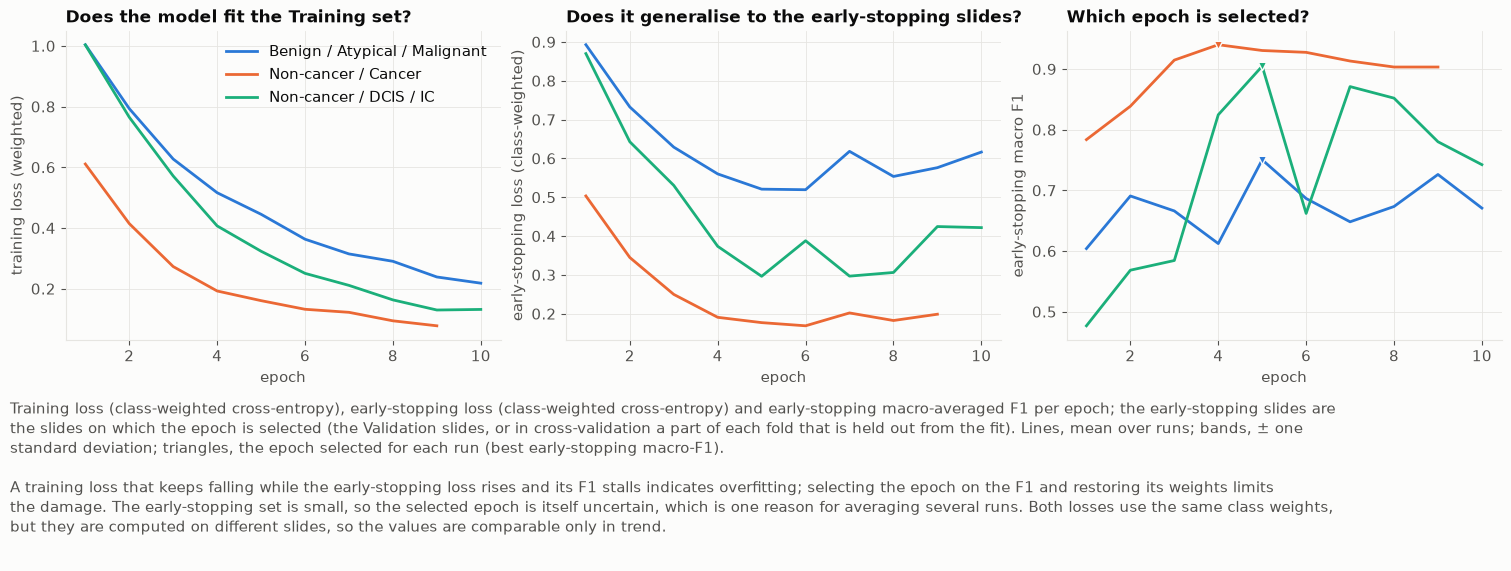

In [9]:
# STEP 1: The curves of every label set
curves = plot_training_curves({name: [run['history']] for name, run in runs.items()}, weighted_val_loss=True)

## 5. Evaluation on the Testing set

The Testing labels are read here for the first time. The probabilities of each model give the predicted class (the highest probability), from which the confusion matrix, accuracy, F1, sensitivity (recall), specificity and precision follow, and the ROC curve and AUROC use the probabilities directly. For more than two classes each measure is computed one class against the rest and averaged over classes (macro); for the binary set the Cancer row is the usual binary view. The 95% intervals come from a bootstrap that resamples patients.

In [10]:
# STEP 1: Predictions on the Testing slides
predictions = {name: predict_testing(runs[name], data, tables[name], class_lists[name], DEVICE) for name in LABEL_SETS}

# STEP 2: All measures, with patient-bootstrap intervals
evaluations = {n: evaluate_predictions(p['y'], p['proba'], class_lists[n]) for n, p in predictions.items()}
views = {n: class_views(p['y'], p['proba'], class_lists[n]) for n, p in predictions.items()}
intervals = {n: bootstrap_views(p['y'], p['proba'], p['patients'], class_lists[n], N_BOOT, SEED) for n, p in predictions.items()}
print({n: f"{len(p['y'])} slides, {len(set(p['patients']))} patients" for n, p in predictions.items()})

{'Benign / Atypical / Malignant': '87 slides, 31 patients', 'Non-cancer / Cancer': '87 slides, 31 patients', 'Non-cancer / DCIS / IC': '87 slides, 31 patients'}


### 5.1 Confusion matrices and ROC curves

One figure per label set: the confusion matrix and the one-vs-rest ROC curves with their AUROC.

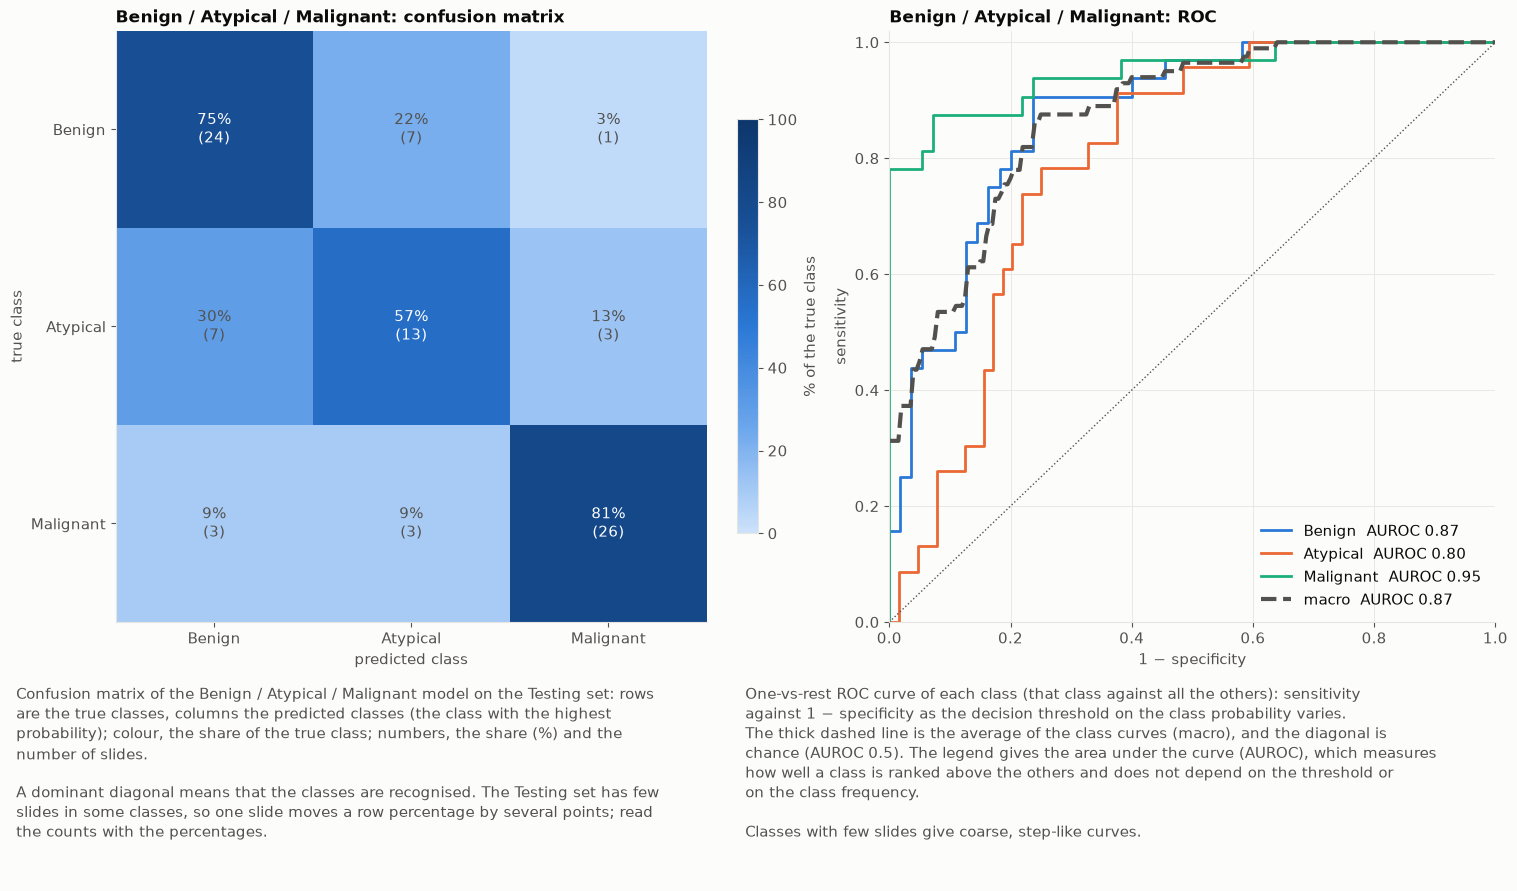

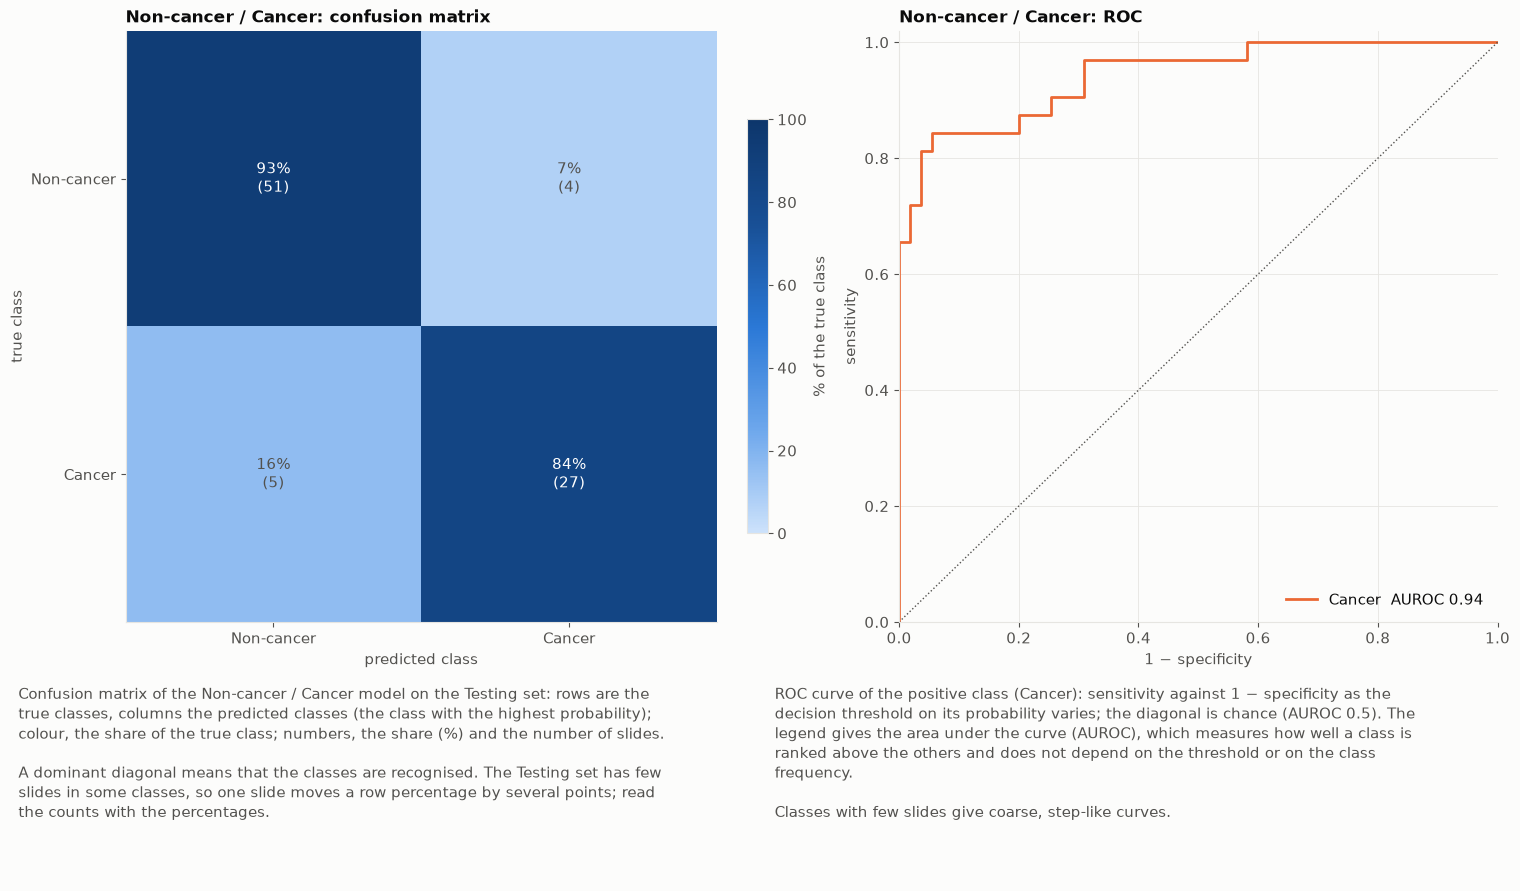

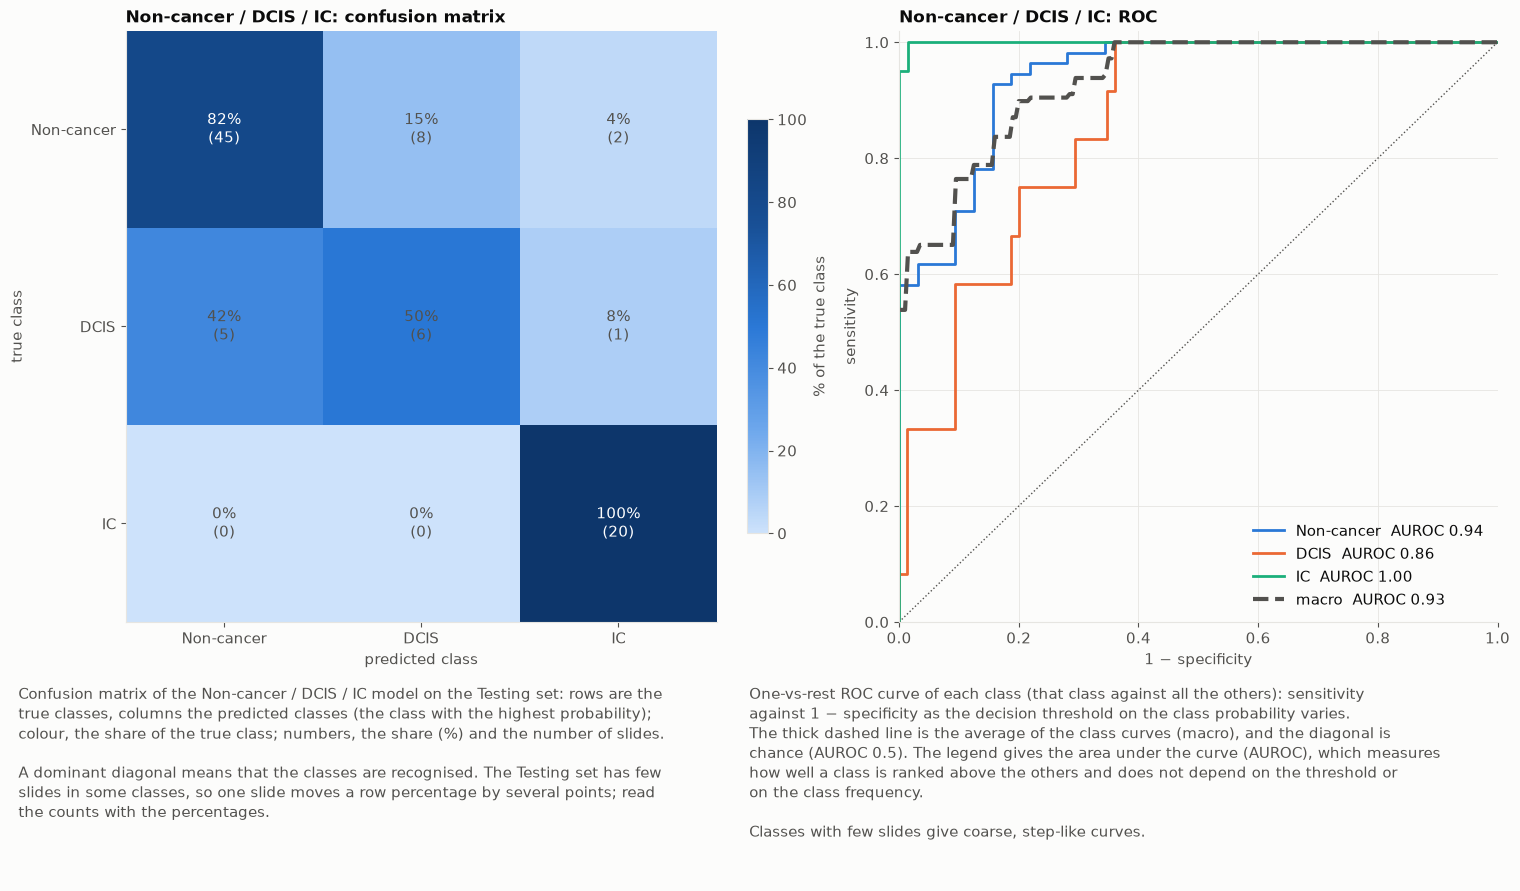

In [11]:
# STEP 1: One figure per label set
figures = {name: plot_final_results(name, evaluations[name]['confusion'], predictions[name]['y'], predictions[name]['proba'], class_lists[name]) for name in LABEL_SETS}

### 5.2 Measures per class

Accuracy, sensitivity (recall), specificity, precision, F1 and AUROC of each class against the rest, with the 95% patient-bootstrap interval. The accuracy of a class row is its one-vs-rest accuracy; the `macro` row has the multi-class accuracy and the unweighted mean of the other measures over classes. Sensitivity is the recall of the class and specificity is the share of the other classes correctly not assigned to it. A measure with a wide interval rests on few slides.

In [12]:
# STEP 1: One table per label set
for name in LABEL_SETS:
    print(name)
    display(format_views(views[name], intervals[name]))

Benign / Atypical / Malignant


,accuracy,sensitivity,specificity,precision,f1,auroc
Benign,"0.793 [0.676, 0.917]","0.750 [0.588, 1.000]","0.818 [0.652, 0.940]","0.706 [0.500, 0.895]","0.727 [0.600, 0.872]","0.873 [0.773, 0.960]"
Atypical,"0.770 [0.681, 0.869]","0.565 [0.250, 0.812]","0.844 [0.711, 0.981]","0.565 [0.406, 0.833]","0.565 [0.350, 0.706]","0.798 [0.701, 0.912]"
Malignant,"0.885 [0.812, 0.958]","0.812 [0.643, 0.964]","0.927 [0.821, 0.986]","0.867 [0.742, 0.966]","0.839 [0.708, 0.933]","0.948 [0.878, 0.996]"
macro,"0.724 [0.627, 0.831]","0.709 [0.621, 0.808]","0.863 [0.806, 0.916]","0.713 [0.630, 0.819]","0.710 [0.602, 0.802]","0.873 [0.801, 0.940]"


Non-cancer / Cancer


,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"0.897 [0.835, 0.961]","0.927 [0.821, 0.986]","0.844 [0.690, 0.971]","0.911 [0.830, 0.985]","0.919 [0.845, 0.971]","0.942 [0.880, 0.992]"
Cancer,"0.897 [0.835, 0.961]","0.844 [0.690, 0.971]","0.927 [0.821, 0.986]","0.871 [0.765, 0.967]","0.857 [0.750, 0.941]","0.942 [0.880, 0.992]"
macro,"0.897 [0.835, 0.961]","0.886 [0.808, 0.963]","0.886 [0.808, 0.963]","0.891 [0.827, 0.958]","0.888 [0.819, 0.957]","0.942 [0.880, 0.992]"


Non-cancer / DCIS / IC


,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"0.828 [0.750, 0.901]","0.818 [0.667, 0.913]","0.844 [0.690, 0.971]","0.900 [0.806, 0.983]","0.857 [0.755, 0.925]","0.940 [0.864, 0.990]"
DCIS,"0.839 [0.773, 0.904]","0.500 [0.200, 0.765]","0.893 [0.829, 0.956]","0.429 [0.167, 0.667]","0.462 [0.190, 0.636]","0.858 [0.725, 0.942]"
IC,"0.966 [0.921, 1.000]","1.000 [1.000, 1.000]","0.955 [0.895, 1.000]","0.870 [0.684, 1.000]","0.930 [0.812, 1.000]","0.999 [0.995, 1.000]"
macro,"0.816 [0.740, 0.886]","0.773 [0.679, 0.855]","0.897 [0.847, 0.945]","0.733 [0.644, 0.806]","0.750 [0.659, 0.811]","0.932 [0.866, 0.975]"


### 5.3 Comparison of the label sets

The macro row of each label set. The sets differ in the number of classes, so accuracy and F1 are not directly comparable across them: chance level is higher with fewer classes. For the binary set the macro row averages the Non-cancer and Cancer rows; the Cancer row of the table above is the positive-class view.

In [13]:
# STEP 1: Macro measures of the three models
summary_across_sets(views).round(3)

,accuracy,sensitivity,specificity,precision,f1,auroc
Benign / Atypical / Malignant,0.724,0.709,0.863,0.713,0.710,0.873
Non-cancer / Cancer,0.897,0.886,0.886,0.891,0.888,0.942
Non-cancer / DCIS / IC,0.816,0.773,0.897,0.733,0.750,0.932


## 6. Save

One classifier per label set is written to its own subfolder, in the format of `save_best_model` (weights, class names, feature scaler, architecture settings and configuration), so each can be loaded with `mil_train.load_classifier`.

In [14]:
# STEP 1: What is needed to reproduce and to reuse each run
config = dict(
    seed=SEED, early_stop_fraction=EARLY_STOP_FRACTION, model_args=MODEL_ARGS, weighting=WEIGHTING, train_args=TRAIN_ARGS, dropout=DROPOUT, tile_dropout=TILE_DROPOUT, n_boot=N_BOOT,
    features_dir=str(FEATURES_DIR), model_name=MODEL_NAME, tile_params=data['tile_params'], device=device_description(DEVICE), label_sets=LABEL_SETS,
    versions=dict(torch=torch.__version__, sklearn=sklearn.__version__, numpy=np.__version__, pandas=pd.__version__), dropped_slides=data['missing'],
)

# STEP 2: Save one classifier per label set
if SAVE_MODELS:
    for name, run in runs.items():
        slug = name.lower().replace(' / ', '_').replace('-', '')
        path = save_best_model({'clam_mb': [run]}, MODEL_DIR / slug, {**config, 'label_set': name, 'classes': class_lists[name]})
        print(f'{name}: saved to', path.resolve())
else:
    print('SAVE_MODELS is False: nothing was written.')

Benign / Atypical / Malignant: saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/benign_atypical_malignant/classifier_model_2026-11-16_06-19-09.pt
Non-cancer / Cancer: saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/noncancer_cancer/classifier_model_2026-11-16_06-19-09.pt
Non-cancer / DCIS / IC: saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/noncancer_dcis_ic/classifier_model_2026-11-16_06-19-09.pt


## 7. Two-stage classifier: Cancer first, then DCIS or IC

The flat Non-cancer / DCIS / IC model of section 4 has to separate three classes at once, and its weakest class is DCIS (low precision). The hierarchical alternative uses the Non-cancer / Cancer model of section 4 as the first stage and a second model, trained only on cancer slides (DCIS and IC), as the second stage. The decision is a cascade: a slide that the first stage assigns to Non-cancer is final, and only the slides that the first stage assigns to Cancer are divided between DCIS and IC by the second stage. The Non-cancer class is therefore decided by the first stage alone, and its measures in this section equal those of the Non-cancer / Cancer model.

Two properties limit what the hierarchy can achieve. The errors of the first stage are inherited: a non-cancer slide that passes the first stage is necessarily labelled DCIS or IC, so the false positives of the Cancer model (its precision is below 1) cannot be corrected by the second stage. And the second stage is trained on few slides (listed below), so its epoch selection is noisy. Whether the hierarchy improves on the flat model is therefore judged on the paired bootstrap of section 8.

### 7.1 Cancer-only model (stage 2)

The second stage is a CLAM-MB trained on the DCIS and IC slides only, with the same split, the same settings and the same class-weighted loss as the other models. The class weights are computed from the fit slides of this model (DCIS and IC) and weight the training loss and the early-stopping loss alike; the Testing slides are not in its table. The table lists the slides it uses, and the weights it trains with are printed.

set,Training,Validation
label,,
DCIS,39,10
IC,89,23


Class weights (sqrt) of the cancer-only model: {'DCIS': np.float32(1.307), 'IC': np.float32(0.865)}
DCIS / IC (stage 2): best epoch 7 of 12, early-stopping macro F1 0.928, balanced accuracy 0.928  (21 s)


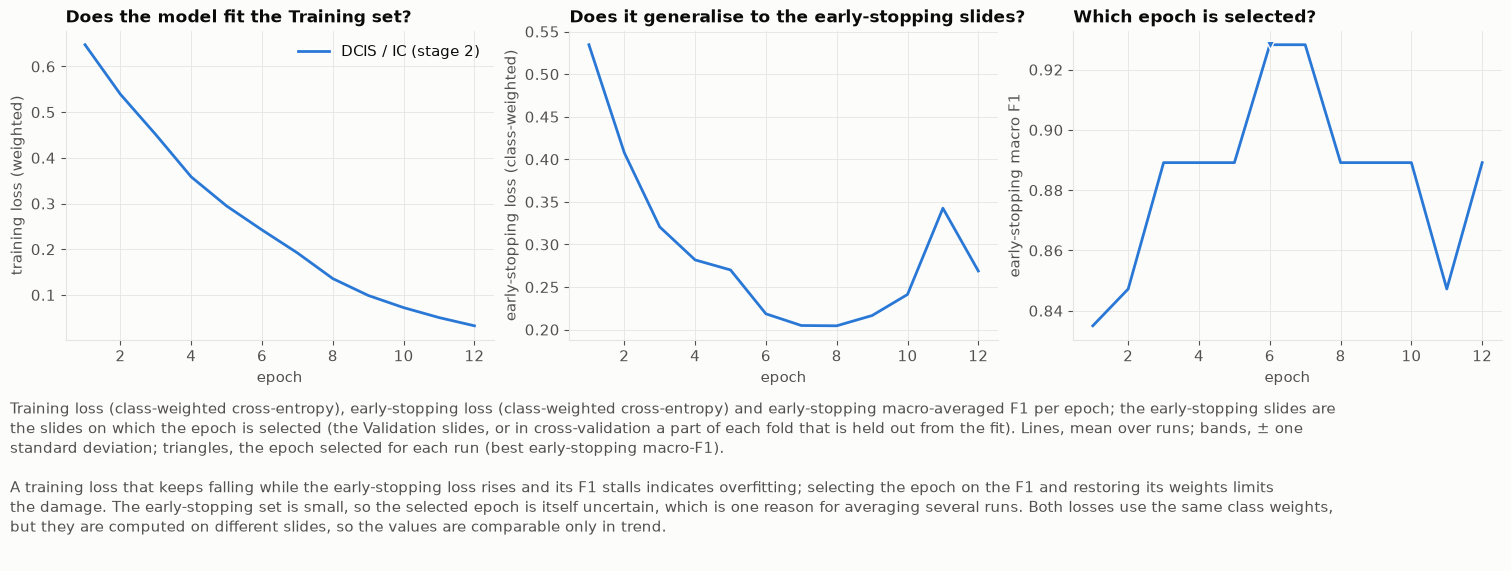

In [15]:
# STEP 1: The second-stage classes (the cancer slides only; the Testing slides are dropped from this table)
STAGE2_MAPPING = {'DCIS': 'DCIS', 'IC': 'IC'}
table2, classes2 = make_stage2_table(split, STAGE2_MAPPING)
assert 'Testing' not in set(table2['set'])

# STEP 2: Slides per class and part
display(pd.crosstab(table2['label'], table2['set']).reindex(classes2)[['Training', 'Validation']])

# STEP 3: The class weights of this model (from its fit slides); the loss is never unweighted
assert WEIGHTING is not None
weights2 = training_class_weights({**data, 'table': table2, 'classes': classes2}, WEIGHTING)
print(f"Class weights ({WEIGHTING}) of the cancer-only model:", dict(zip(classes2, weights2.numpy().round(3))))

# STEP 4: Train the second-stage model with the constants of section 2
t0 = time()
run2 = train_final(data, table2, classes2, DEVICE, SEED, WEIGHTING, MODEL_ARGS, TRAIN_ARGS, DROPOUT, TILE_DROPOUT, verbose=False)
print(f"DCIS / IC (stage 2): best epoch {run2['best_epoch']} of {run2['epochs_run']}, early-stopping macro F1 {run2['best']['val_macro_f1']:.3f}, balanced accuracy {run2['best']['val_balanced_accuracy']:.3f}  ({time() - t0:.0f} s)")

# STEP 5: Training curves (class-weighted training and early-stopping loss)
curves2 = plot_training_curves({'DCIS / IC (stage 2)': [run2['history']]}, weighted_val_loss=True)

### 7.2 Cascade decisions and confusion matrix

Both stages are applied to every Testing slide. The predicted class follows the cascade: Non-cancer if the first stage assigns the slide to Non-cancer, otherwise the class with the highest probability of the second stage. The slides are distributed over the 3  3 confusion matrix with these decisions, and accuracy, sensitivity, specificity, precision and F1 are computed from that matrix.

The AUROC and the ROC curves need a continuous score for each class and use the chain rule, P(DCIS) = P(Cancer)  P(DCIS | cancer) and likewise for IC, with P(Non-cancer) from the first stage. The argmax of these products is not used as the decision: when the second stage is undecided, the cancer probability is split between DCIS and IC and each can fall below P(Non-cancer), which would send a slide that the first stage calls Cancer back to Non-cancer. The assertion below checks that the cascade never does so.

In [16]:
# STEP 1: The same Testing slides, in the same order, for both stages and for the flat model
FLAT, BINARY = 'Non-cancer / DCIS / IC', 'Non-cancer / Cancer'
slides = predictions[FLAT]['test']['slide'].tolist()
assert slides == predictions[BINARY]['test']['slide'].tolist()
proba_binary = predictions[BINARY]['proba']

# STEP 2: Second-stage probabilities of every Testing slide, the cascade decisions and the scores for the ROC
proba2 = predict_ensemble([run2], data, slides, DEVICE)['proba']
pred_two = cascade_predict(proba_binary, proba2)
score_two = combine_two_stage(proba_binary, proba2)
assert ((pred_two == 0) == (proba_binary.argmax(1) == 0)).all(), 'Non-cancer must be decided by the first stage alone'

# STEP 3: Confusion matrix of the cascade decisions (rows true class, columns predicted class)
TWO = 'Two-stage: Non-cancer / Cancer, then DCIS / IC'
y_two, K = predictions[FLAT]['y'], len(class_lists[FLAT])
confusion_two = pd.DataFrame(np.bincount(y_two * K + pred_two, minlength=K * K).reshape(K, K), index=class_lists[FLAT], columns=class_lists[FLAT])
confusion_two.index.name, confusion_two.columns.name = 'true', 'predicted'
display(confusion_two)

# STEP 4: The measures from the cascade decisions (AUROC from the scores), in the layout of the other models
predictions[TWO] = {**predictions[FLAT], 'proba': score_two, 'pred': pred_two}
class_lists[TWO] = class_lists[FLAT]
views[TWO] = class_views(y_two, score_two, class_lists[TWO], pred_two)
intervals[TWO] = bootstrap_views(y_two, score_two, predictions[TWO]['patients'], class_lists[TWO], N_BOOT, SEED, pred_two)

# STEP 5: The Non-cancer row must equal that of the Non-cancer / Cancer model (its measures, read for Non-cancer)
for measure in ['sensitivity', 'specificity', 'precision']:
    assert np.isclose(views[TWO].loc['Non-cancer', measure], views[BINARY].loc['Non-cancer', measure]), measure
print('Non-cancer row identical to the Non-cancer / Cancer model: sensitivity', round(views[TWO].loc['Non-cancer', 'sensitivity'], 3))

predicted,Non-cancer,DCIS,IC
true,,,
Non-cancer,51,1,3
DCIS,5,6,1
IC,0,0,20


Non-cancer row identical to the Non-cancer / Cancer model: sensitivity 0.927


### 7.3 Confusion matrix, ROC and measures of the two-stage model

The figure and the table have the layout of section 5, on the same Testing slides and the same three classes, so they can be read directly against those of the flat model. The confusion matrix and the measures come from the cascade decisions; the ROC curves and the AUROC from the chain-rule scores.

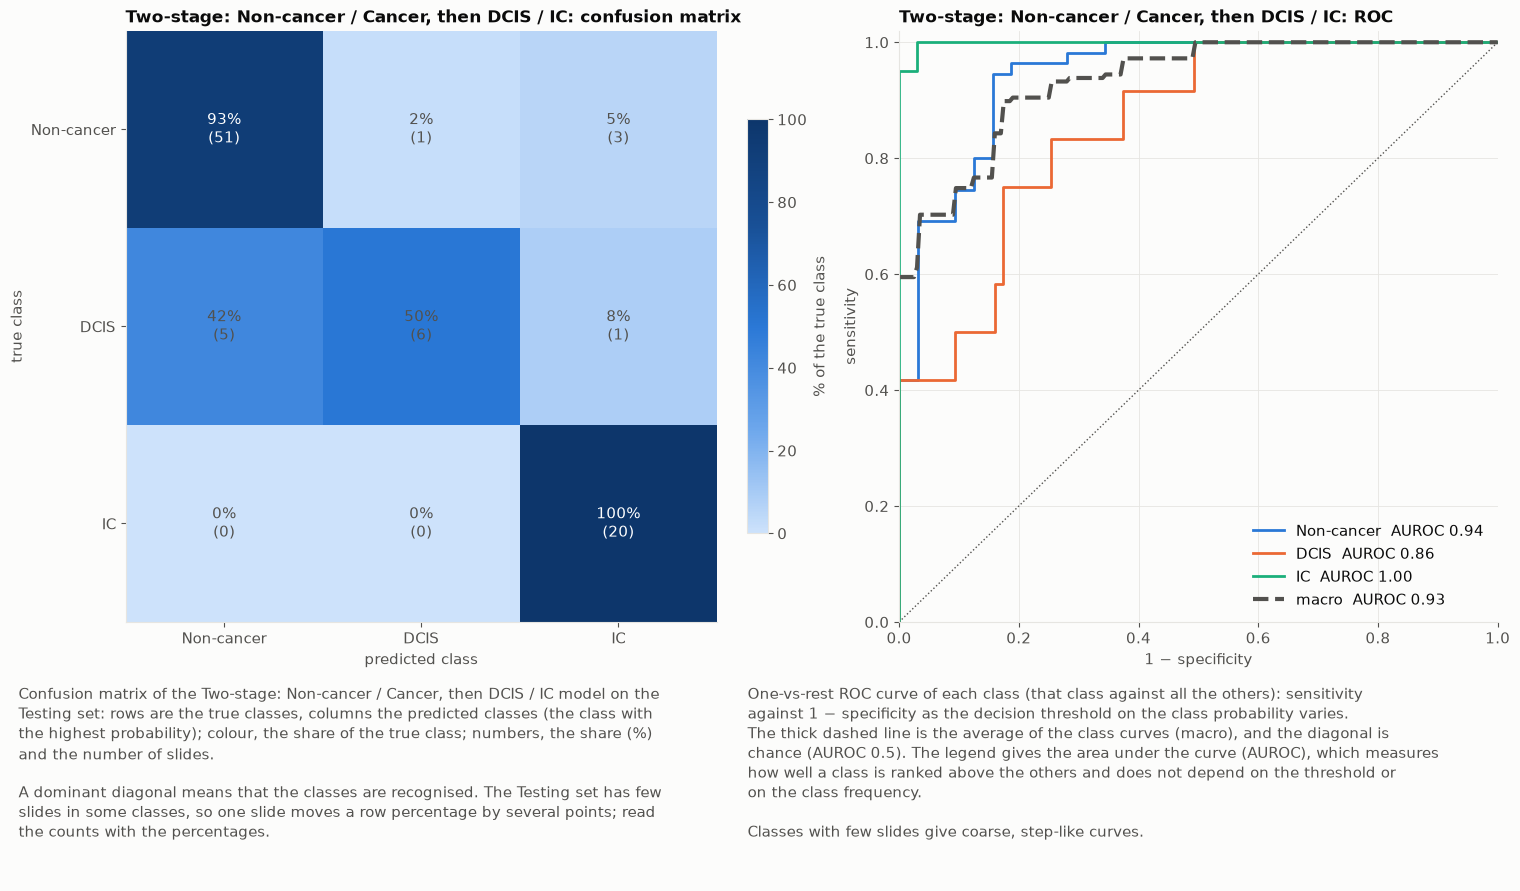

,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"0.897 [0.835, 0.961]","0.927 [0.821, 0.986]","0.844 [0.690, 0.971]","0.911 [0.830, 0.985]","0.919 [0.845, 0.971]","0.942 [0.880, 0.992]"
DCIS,"0.920 [0.865, 0.974]","0.500 [0.200, 0.765]","0.987 [0.954, 1.000]","0.857 [0.600, 1.000]","0.632 [0.333, 0.824]","0.857 [0.723, 0.954]"
IC,"0.954 [0.903, 0.990]","1.000 [1.000, 1.000]","0.940 [0.870, 0.988]","0.833 [0.667, 0.962]","0.909 [0.800, 0.980]","0.999 [0.993, 1.000]"
macro,"0.885 [0.822, 0.950]","0.809 [0.718, 0.888]","0.924 [0.876, 0.972]","0.867 [0.789, 0.951]","0.820 [0.720, 0.889]","0.932 [0.873, 0.978]"


In [17]:
# STEP 1: Confusion matrix (cascade decisions) and one-vs-rest ROC curves (chain-rule scores)
fig_two = plot_final_results(TWO, confusion_two, y_two, score_two, class_lists[TWO])

# STEP 2: Measures per class with patient-bootstrap intervals
display(format_views(views[TWO], intervals[TWO]))

### 7.4 The second stage on its own

To separate the quality of the second stage from the errors inherited from the first, the DCIS / IC model is evaluated on the Testing slides that are truly cancer (DCIS or IC) only. Any difference between this table and the DCIS and IC rows of section 7.3 is due to the first stage. The number of non-cancer slides that the first stage sends to the second is printed as well.

Non-cancer Testing slides passed to the second stage: 4 of 55


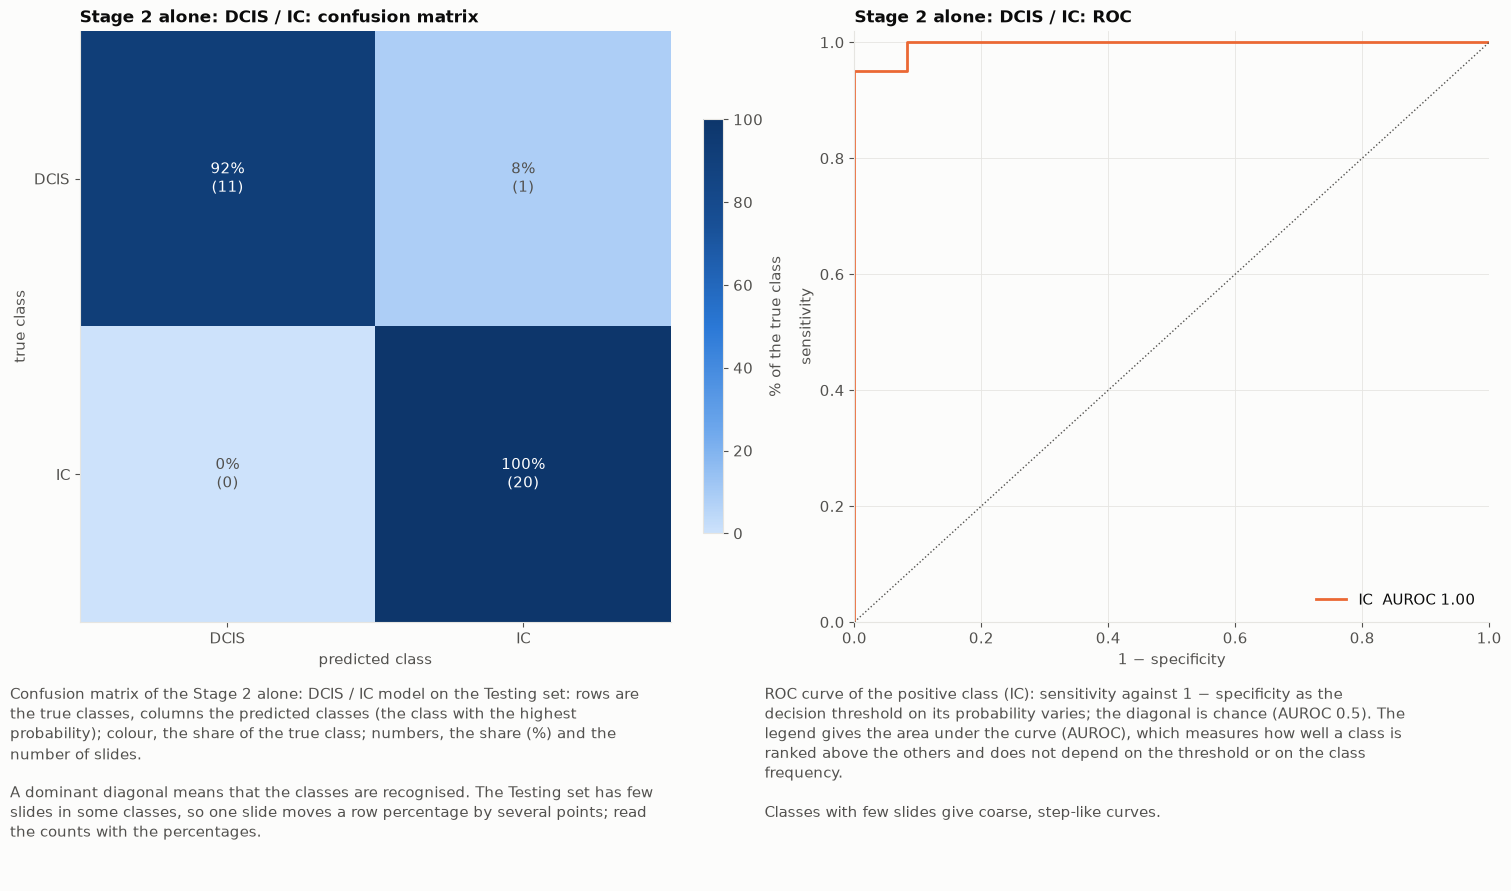

,accuracy,sensitivity,specificity,precision,f1,auroc
DCIS,"0.969 [0.897, 1.000]","0.917 [0.750, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.957 [0.857, 1.000]","0.996 [0.974, 1.000]"
IC,"0.969 [0.897, 1.000]","1.000 [1.000, 1.000]","0.917 [0.750, 1.000]","0.952 [0.818, 1.000]","0.976 [0.900, 1.000]","0.996 [0.974, 1.000]"
macro,"0.969 [0.897, 1.000]","0.958 [0.875, 1.000]","0.958 [0.875, 1.000]","0.976 [0.909, 1.000]","0.966 [0.884, 1.000]","0.996 [0.974, 1.000]"


In [18]:
# STEP 1: Truly cancer Testing slides (classes 1 and 2 of the 3-class labels) and their DCIS / IC labels
mask = y_two > 0
y2, p2, patients2 = y_two[mask] - 1, proba2[mask], predictions[TWO]['patients'][mask]

# STEP 2: Non-cancer slides that the first stage passes on as Cancer
passed = int(((y_two == 0) & (pred_two > 0)).sum())
print(f"Non-cancer Testing slides passed to the second stage: {passed} of {int((y_two == 0).sum())}")

# STEP 3: Confusion matrix, ROC and measures of the second stage
views2 = class_views(y2, p2, classes2)
intervals2 = bootstrap_views(y2, p2, patients2, classes2, N_BOOT, SEED)
fig2 = plot_final_results('Stage 2 alone: DCIS / IC', evaluate_predictions(y2, p2, classes2)['confusion'], y2, p2, classes2)
display(format_views(views2, intervals2))

### 7.5 Confusion matrix of the two-stage process

The final label of every Testing slide is taken from the stage that decided it, without combining probabilities. The first stage assigns Non-cancer or Cancer (the class with the highest probability of the Non-cancer / Cancer model); only the slides assigned to Cancer receive the decision of the second stage, DCIS or IC (the class with the highest probability of the DCIS / IC model). The 3 x 3 confusion matrix counts the true class against this final decision.

The errors of the first stage are inherited: a non-cancer slide assigned to Cancer is necessarily labelled DCIS or IC, and a cancer slide assigned to Non-cancer is final. DCIS has few Testing slides, so a single slide changes its row by several percentage points.

final decision,Non-cancer,DCIS,IC
true,,,
Non-cancer,51,1,3
DCIS,5,6,1
IC,0,0,20


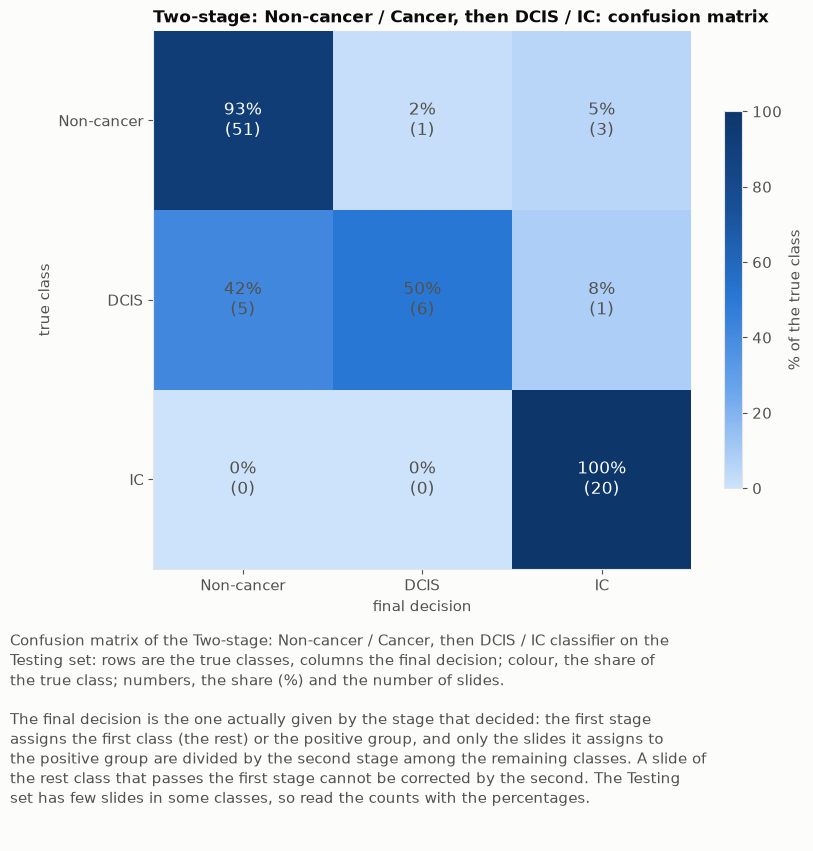

In [19]:
# STEP 1: Decision of each stage (stage 1: 0 Non-cancer, 1 Cancer; stage 2: 0 DCIS, 1 IC)
stage1 = proba_binary.argmax(1)
stage2 = proba2.argmax(1)

# STEP 2: Final label: Non-cancer from stage 1, otherwise the class given by stage 2
final = np.where(stage1 == 1, 1 + stage2, 0)
assert (final == pred_two).all(), 'The stage decisions must give the cascade of section 7.2'

# STEP 3: Confusion matrix of the final decisions (rows true class, columns final decision)
confusion_stages = pd.DataFrame(np.bincount(y_two * K + final, minlength=K * K).reshape(K, K), index=class_lists[FLAT], columns=class_lists[FLAT])
confusion_stages.index.name, confusion_stages.columns.name = 'true', 'final decision'
display(confusion_stages)

# STEP 4: Figure
fig_stages = plot_two_stage_confusion(TWO, confusion_stages)

## 7.6 Experiment: ADH as a class of its own

In sections 4 to 7.5 atypical ductal hyperplasia (ADH) is part of Non-cancer. This experiment gives it its own class and compares two ways of obtaining the four classes Non-cancer, ADH, DCIS and IC. In the direct model one CLAM-MB separates the four classes at once. In the two-stage model the first stage separates Non-cancer from Cancer, where ADH, DCIS and IC all count as Cancer, and a second stage trained on ADH, DCIS and IC slides only divides the slides passed on by the first stage among these three classes. Non-cancer groups the classes N, PB, UDH and FEA. All models use the split of section 3.2 and the constants of section 2, so the Testing set is used for reporting only.

ADH is a small class, so its Testing measures and the intervals around them rest on very few slides; the table lists the slides per class and part.

In [20]:
# STEP 1: The groupings (the order of the groups is the order of the model outputs)
FOUR_MAPPING = {'N': 'Non-cancer', 'PB': 'Non-cancer', 'UDH': 'Non-cancer', 'FEA': 'Non-cancer', 'ADH': 'ADH', 'DCIS': 'DCIS', 'IC': 'IC'}
STAGE1_ADH_MAPPING = {'N': 'Non-cancer', 'PB': 'Non-cancer', 'UDH': 'Non-cancer', 'FEA': 'Non-cancer', 'ADH': 'Cancer', 'DCIS': 'Cancer', 'IC': 'Cancer'}
STAGE2_ADH_MAPPING = {'ADH': 'ADH', 'DCIS': 'DCIS', 'IC': 'IC'}
ADH4 = 'Non-cancer / ADH / DCIS / IC'
ADH_STAGE1 = 'Non-cancer / Cancer (ADH as cancer)'
ADH_STAGE2 = 'ADH / DCIS / IC (stage 2)'
ADH_TWO = 'Two-stage (ADH as cancer): Non-cancer / Cancer, then ADH / DCIS / IC'

# STEP 2: Relabelled tables and the slides per group and part
table_adh4, classes_adh4 = relabel_table(split, FOUR_MAPPING)
table_adh1, classes_adh1 = relabel_table(split, STAGE1_ADH_MAPPING)
table_adh2, classes_adh2 = make_stage2_table(split, STAGE2_ADH_MAPPING)
assert 'Testing' not in set(table_adh2['set'])
display(pd.crosstab(table_adh4['label'], table_adh4['set']).reindex(classes_adh4)[['Training', 'Validation', 'Testing']])

set,Training,Validation,Testing
label,,,
Non-cancer,210,53,43
ADH,29,7,12
DCIS,39,10,12
IC,89,23,20


### 7.6.1 Direct four-class model

One CLAM-MB is trained on the four classes with the constants of section 2 and the class-weighted loss (weights from its fit slides). It is evaluated on the Testing set as in section 5: confusion matrix, one-vs-rest ROC curves and the measures per class with patient-bootstrap intervals.

Non-cancer / ADH / DCIS / IC: best epoch 7 of 12, early-stopping macro F1 0.823, balanced accuracy 0.781  (63 s)


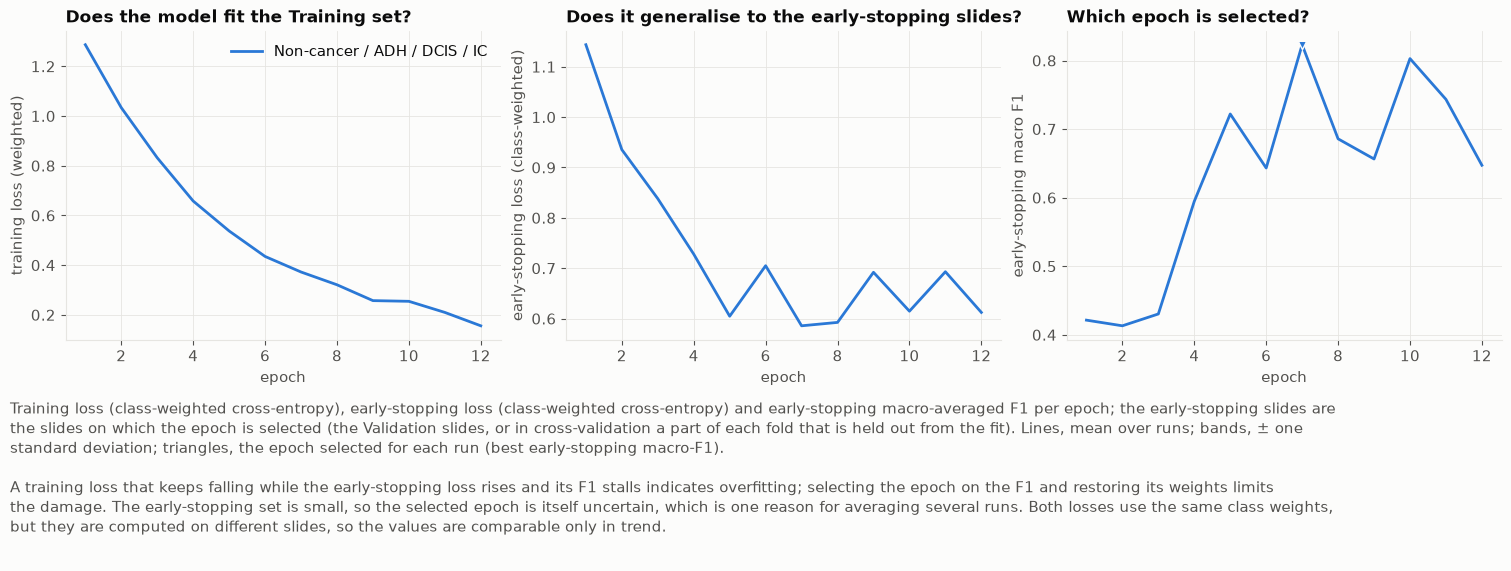

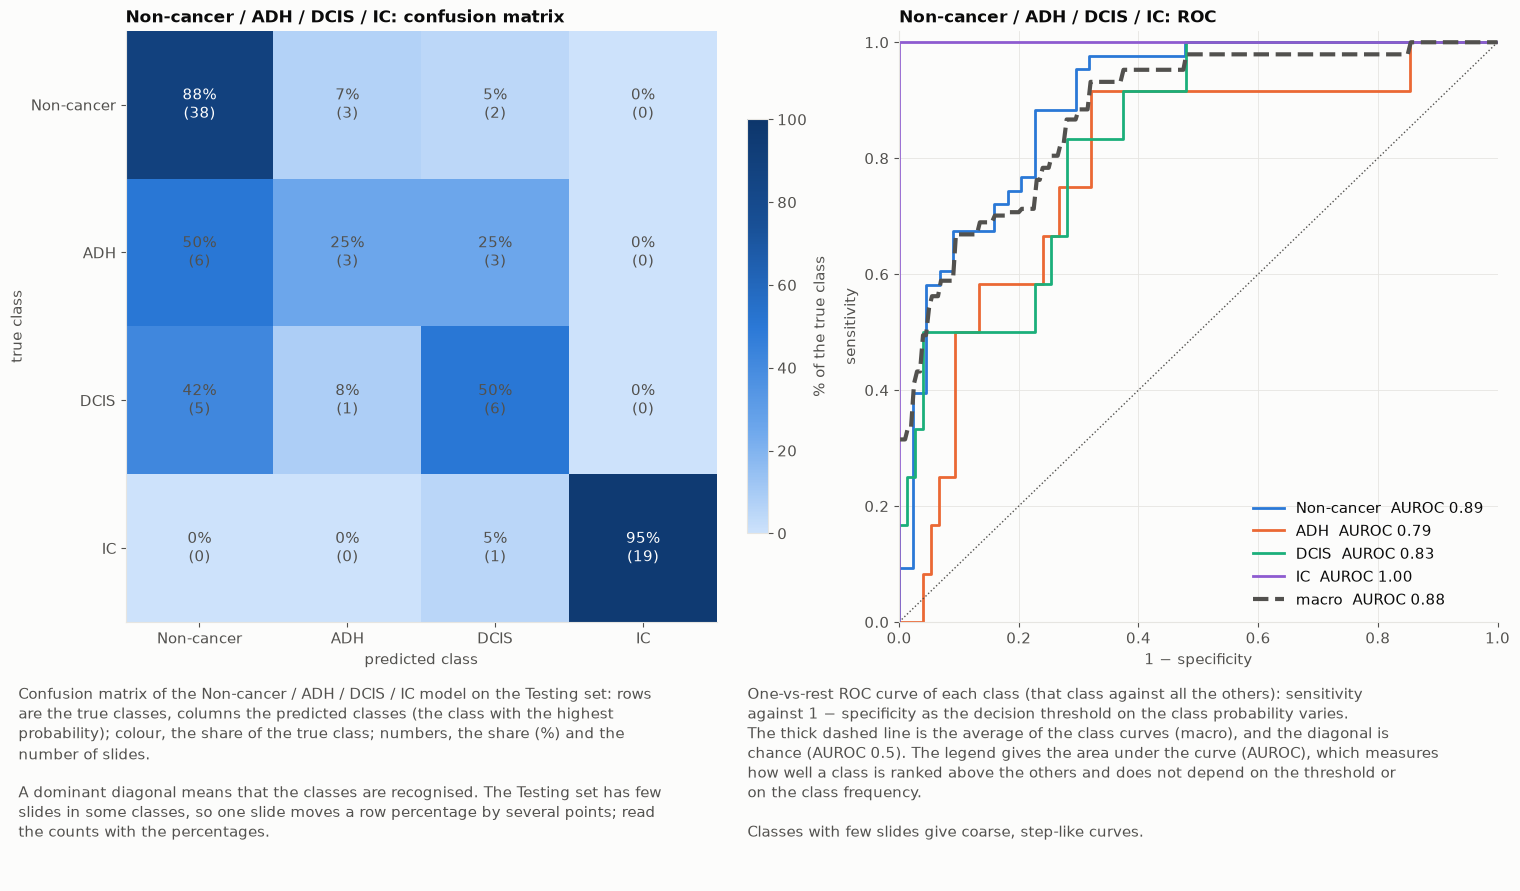

,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"0.816 [0.708, 0.917]","0.884 [0.756, 1.000]","0.750 [0.571, 0.906]","0.776 [0.658, 0.889]","0.826 [0.712, 0.919]","0.895 [0.810, 0.965]"
ADH,"0.851 [0.788, 0.922]","0.250 [0.000, 0.600]","0.947 [0.887, 1.000]","0.429 [0.000, 1.000]","0.316 [0.000, 0.636]","0.786 [0.636, 0.917]"
DCIS,"0.862 [0.784, 0.937]","0.500 [0.143, 0.818]","0.920 [0.859, 0.968]","0.500 [0.125, 0.778]","0.500 [0.143, 0.737]","0.832 [0.681, 0.945]"
IC,"0.989 [0.959, 1.000]","0.950 [0.833, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.974 [0.909, 1.000]","1.000 [1.000, 1.000]"
macro,"0.759 [0.655, 0.863]","0.646 [0.517, 0.787]","0.904 [0.855, 0.950]","0.676 [0.525, 0.853]","0.654 [0.518, 0.783]","0.878 [0.810, 0.945]"


In [21]:
# STEP 1: Train the direct model
t0 = time()
run_adh4 = train_final(data, table_adh4, classes_adh4, DEVICE, SEED, WEIGHTING, MODEL_ARGS, TRAIN_ARGS, DROPOUT, TILE_DROPOUT, verbose=False)
print(f"{ADH4}: best epoch {run_adh4['best_epoch']} of {run_adh4['epochs_run']}, early-stopping macro F1 {run_adh4['best']['val_macro_f1']:.3f}, balanced accuracy {run_adh4['best']['val_balanced_accuracy']:.3f}  ({time() - t0:.0f} s)")

# STEP 2: Testing predictions and measures
predictions[ADH4] = predict_testing(run_adh4, data, table_adh4, classes_adh4, DEVICE)
class_lists[ADH4] = classes_adh4
y_adh, patients_adh = predictions[ADH4]['y'], predictions[ADH4]['patients']
evaluation_adh4 = evaluate_predictions(y_adh, predictions[ADH4]['proba'], classes_adh4)
views[ADH4] = class_views(y_adh, predictions[ADH4]['proba'], classes_adh4)
intervals[ADH4] = bootstrap_views(y_adh, predictions[ADH4]['proba'], patients_adh, classes_adh4, N_BOOT, SEED)

# STEP 3: Figure and table
curves_adh4 = plot_training_curves({ADH4: [run_adh4['history']]}, weighted_val_loss=True)
fig_adh4 = plot_final_results(ADH4, evaluation_adh4['confusion'], y_adh, predictions[ADH4]['proba'], classes_adh4)
display(format_views(views[ADH4], intervals[ADH4]))

### 7.6.2 Two-stage model: training

The first stage is a CLAM-MB for Non-cancer against Cancer, where Cancer contains ADH, DCIS and IC. The second stage is a CLAM-MB trained on the ADH, DCIS and IC slides only; the Testing slides are not in its table. Both use the same split, the same settings and the class-weighted loss, with the weights computed from the fit slides of each model.

set,Training,Validation
label,,
ADH,29,7
DCIS,39,10
IC,89,23


Class weights (sqrt) of the second stage: {'ADH': np.float32(1.384), 'DCIS': np.float32(1.194), 'IC': np.float32(0.79)}
Non-cancer / Cancer (ADH as cancer): best epoch 14 of 19, early-stopping macro F1 0.923, balanced accuracy 0.925  (94 s)
ADH / DCIS / IC (stage 2): best epoch 19 of 24, early-stopping macro F1 0.796, balanced accuracy 0.790  (49 s)


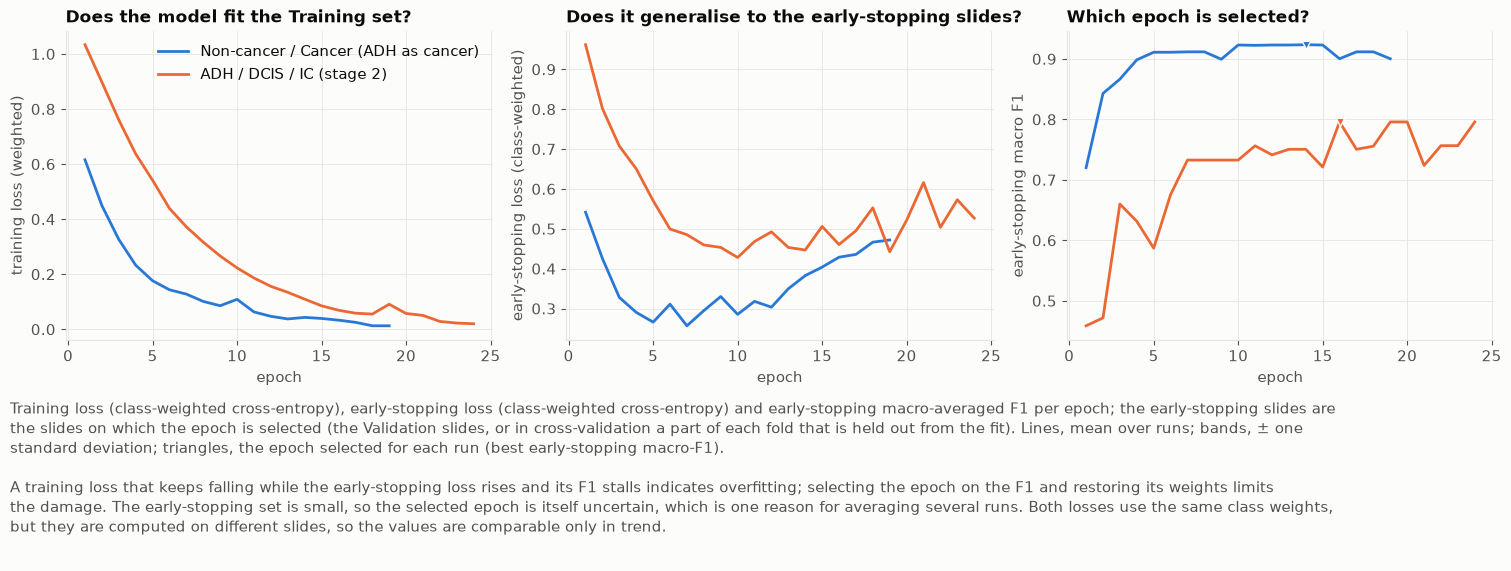

In [22]:
# STEP 1: Class weights of the second stage (the loss is never unweighted)
assert WEIGHTING is not None
weights_adh2 = training_class_weights({**data, 'table': table_adh2, 'classes': classes_adh2}, WEIGHTING)
display(pd.crosstab(table_adh2['label'], table_adh2['set']).reindex(classes_adh2)[['Training', 'Validation']])
print(f"Class weights ({WEIGHTING}) of the second stage:", dict(zip(classes_adh2, weights_adh2.numpy().round(3))))

# STEP 2: Train both stages with the constants of section 2
run_adh1, run_adh2 = None, None
for label, table, classes in [(ADH_STAGE1, table_adh1, classes_adh1), (ADH_STAGE2, table_adh2, classes_adh2)]:
    t0 = time()
    run = train_final(data, table, classes, DEVICE, SEED, WEIGHTING, MODEL_ARGS, TRAIN_ARGS, DROPOUT, TILE_DROPOUT, verbose=False)
    print(f"{label}: best epoch {run['best_epoch']} of {run['epochs_run']}, early-stopping macro F1 {run['best']['val_macro_f1']:.3f}, balanced accuracy {run['best']['val_balanced_accuracy']:.3f}  ({time() - t0:.0f} s)")
    if label == ADH_STAGE1:
        run_adh1 = run
    else:
        run_adh2 = run

# STEP 3: Training curves
curves_adh_stages = plot_training_curves({ADH_STAGE1: [run_adh1['history']], ADH_STAGE2: [run_adh2['history']]}, weighted_val_loss=True)

### 7.6.3 Two-stage model: confusion matrix

Each Testing slide receives the decision of the first stage (Non-cancer or Cancer). Only the slides assigned to Cancer receive the decision of the second stage (ADH, DCIS or IC); the final label is the one given by the stage that decided, without combining probabilities. The first stage therefore decides Non-cancer alone, and a Non-cancer slide that it assigns to Cancer is necessarily labelled ADH, DCIS or IC.

final decision,Non-cancer,ADH,DCIS,IC
true,,,,
Non-cancer,35,2,6,0
ADH,2,5,5,0
DCIS,1,1,10,0
IC,0,0,1,19


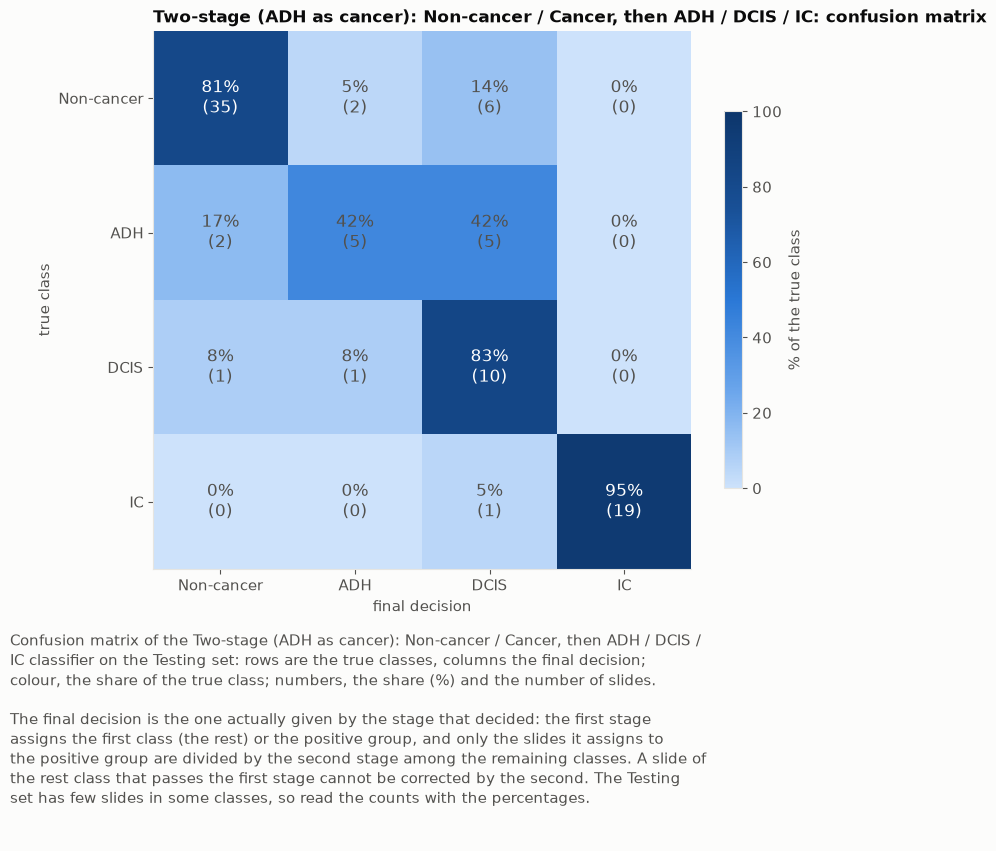

In [23]:
# STEP 1: The same Testing slides, in the same order, for both stages and for the direct model
slides_adh = predictions[ADH4]['test']['slide'].tolist()
assert slides_adh == table_adh1[table_adh1['set'] == 'Testing']['slide'].tolist()
proba_adh1 = predict_testing(run_adh1, data, table_adh1, classes_adh1, DEVICE)['proba']
proba_adh2 = predict_ensemble([run_adh2], data, slides_adh, DEVICE)['proba']

# STEP 2: Decision of each stage (stage 1: 0 Non-cancer, 1 Cancer; stage 2: 0 ADH, 1 DCIS, 2 IC) and the final label
stage1_adh = proba_adh1.argmax(1)
stage2_adh = proba_adh2.argmax(1)
final_adh = np.where(stage1_adh == 1, 1 + stage2_adh, 0)
assert (final_adh == cascade_predict(proba_adh1, proba_adh2)).all()

# STEP 3: Confusion matrix of the final decisions (rows true class, columns final decision)
K_adh = len(classes_adh4)
confusion_adh_two = pd.DataFrame(np.bincount(y_adh * K_adh + final_adh, minlength=K_adh * K_adh).reshape(K_adh, K_adh), index=classes_adh4, columns=classes_adh4)
confusion_adh_two.index.name, confusion_adh_two.columns.name = 'true', 'final decision'
display(confusion_adh_two)
fig_adh_two = plot_two_stage_confusion(ADH_TWO, confusion_adh_two)

### 7.6.4 Measures and comparison with the direct model

The measures of the two-stage model follow the layout of section 7.3: the decisions are those of the cascade and the AUROC uses the chain-rule scores, P(ADH) = P(Cancer) P(ADH | cancer) and likewise for DCIS and IC. The difference (two-stage minus direct) comes with a 95% interval from a paired patient bootstrap on the same Testing slides. An interval that contains zero is not distinguishable from no change at this sample size, and ADH, with the fewest slides, changes by several points with a single slide.

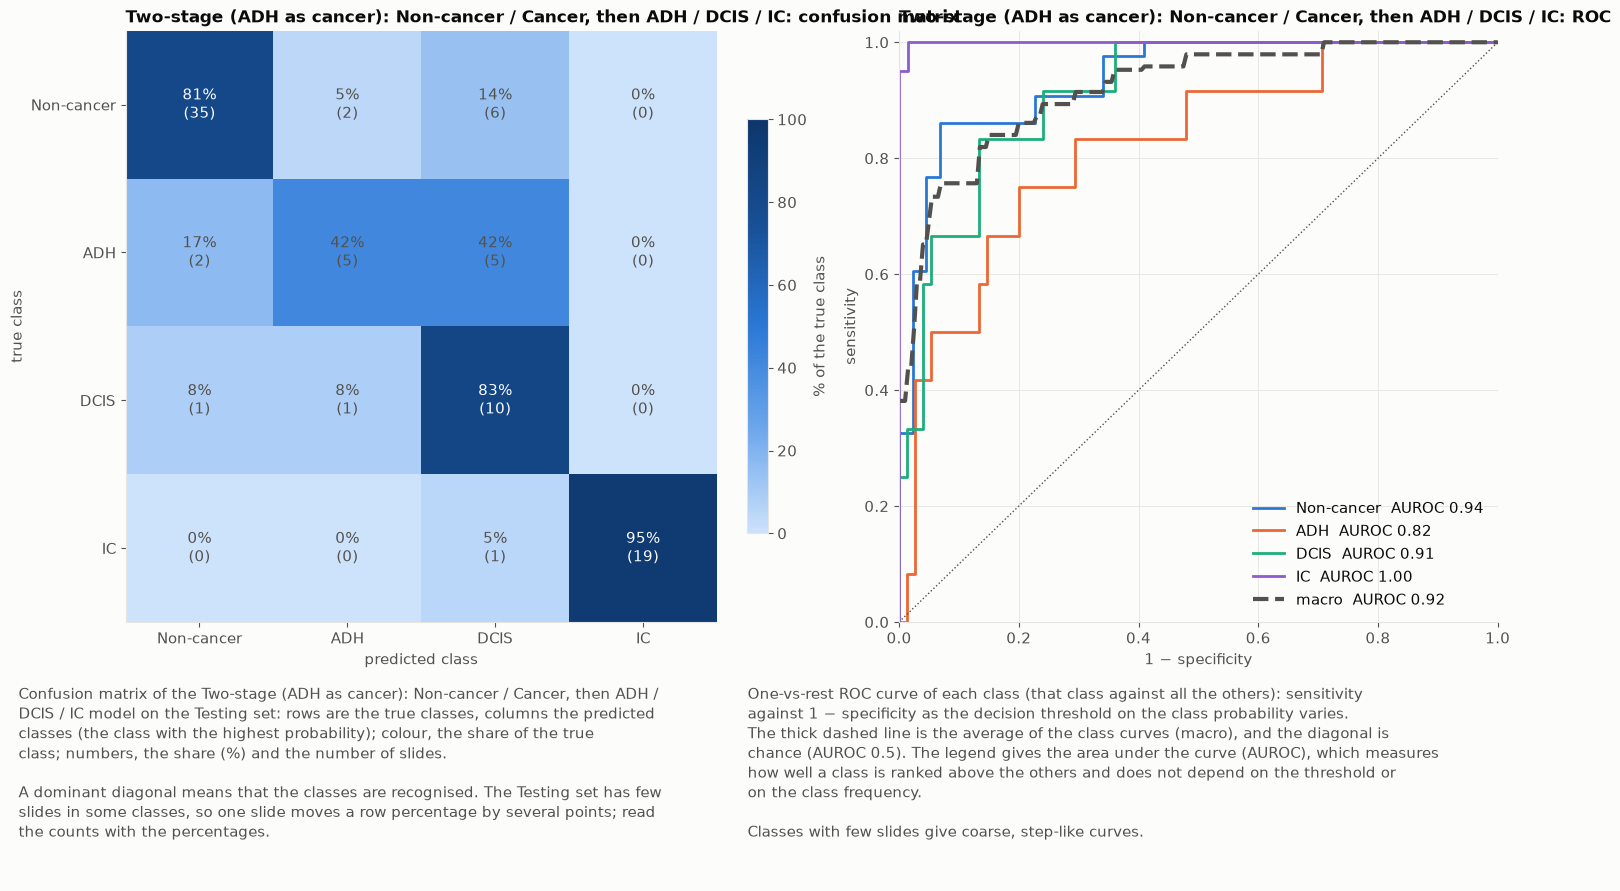

,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"0.874 [0.807, 0.944]","0.814 [0.686, 0.946]","0.932 [0.854, 1.000]","0.921 [0.824, 1.000]","0.864 [0.782, 0.937]","0.936 [0.872, 0.988]"
ADH,"0.885 [0.828, 0.941]","0.417 [0.000, 0.750]","0.960 [0.927, 1.000]","0.625 [0.000, 1.000]","0.500 [0.000, 0.744]","0.822 [0.677, 0.945]"
DCIS,"0.839 [0.741, 0.932]","0.833 [0.555, 1.000]","0.840 [0.738, 0.928]","0.455 [0.227, 0.682]","0.588 [0.333, 0.786]","0.912 [0.819, 0.978]"
IC,"0.989 [0.959, 1.000]","0.950 [0.833, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.974 [0.909, 1.000]","0.999 [0.995, 1.000]"
macro,"0.793 [0.694, 0.891]","0.753 [0.627, 0.863]","0.933 [0.900, 0.965]","0.750 [0.594, 0.862]","0.732 [0.596, 0.834]","0.917 [0.862, 0.967]"


,accuracy,sensitivity,specificity,precision,f1,auroc
Direct,0.759,0.646,0.904,0.676,0.654,0.878
Two-stage,0.793,0.753,0.933,0.750,0.732,0.917


,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"+0.057 [+0.000, +0.114]","-0.070 [-0.143, +0.043]","+0.182 [+0.050, +0.340]","+0.146 [+0.054, +0.237]","+0.038 [-0.003, +0.089]","+0.041 [+0.005, +0.082]"
ADH,"+0.034 [-0.023, +0.078]","+0.167 [-0.300, +0.588]","+0.013 [-0.029, +0.057]","+0.196 [-0.200, +0.545]","+0.184 [-0.261, +0.548]","+0.037 [-0.045, +0.105]"
DCIS,"-0.023 [-0.074, +0.022]","+0.333 [+0.000, +0.667]","-0.080 [-0.156, -0.014]","-0.045 [-0.193, +0.143]","+0.088 [-0.067, +0.292]","+0.080 [-0.003, +0.203]"
IC,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","-0.001 [-0.005, +0.000]"
macro,"+0.034 [-0.016, +0.073]","+0.108 [-0.016, +0.228]","+0.029 [+0.003, +0.059]","+0.074 [-0.034, +0.184]","+0.078 [-0.041, +0.180]","+0.039 [+0.005, +0.080]"


In [24]:
# STEP 1: Scores for the ROC, the measures with patient-bootstrap intervals
score_adh_two = combine_two_stage(proba_adh1, proba_adh2)
predictions[ADH_TWO] = {**predictions[ADH4], 'proba': score_adh_two, 'pred': final_adh}
class_lists[ADH_TWO] = classes_adh4
views[ADH_TWO] = class_views(y_adh, score_adh_two, classes_adh4, final_adh)
intervals[ADH_TWO] = bootstrap_views(y_adh, score_adh_two, patients_adh, classes_adh4, N_BOOT, SEED, final_adh)
fig_adh_two_roc = plot_final_results(ADH_TWO, confusion_adh_two, y_adh, score_adh_two, classes_adh4)
display(format_views(views[ADH_TWO], intervals[ADH_TWO]))

# STEP 2: Direct against two-stage: macro measures and the paired bootstrap of the difference (two-stage minus direct)
proba_adh4 = predictions[ADH4]['proba']
display(summary_across_sets({'Direct': views[ADH4], 'Two-stage': views[ADH_TWO]}).round(3))
differences_adh = paired_bootstrap_views(y_adh, score_adh_two, final_adh, proba_adh4, proba_adh4.argmax(1), patients_adh, classes_adh4, N_BOOT, SEED)
display(format_differences(differences_adh))

### 7.6.5 Save

The three classifiers of the experiment are written in the format of `save_best_model`, each to its own subfolder; the configuration of the second stage records the first stage so that the pair can be loaded together.

In [25]:
# STEP 1: Save the direct model and the two stages
if SAVE_MODELS:
    for run, folder, label_set, classes, extra in [
        (run_adh4, 'adh_four_class', ADH4, classes_adh4, {}),
        (run_adh1, 'adh_stage1_non-cancer_cancer', ADH_STAGE1, classes_adh1, {}),
        (run_adh2, 'adh_stage2_adh_dcis_ic', ADH_STAGE2, classes_adh2, {'first_stage': 'adh_stage1_non-cancer_cancer'}),
    ]:
        path = save_best_model({'clam_mb': [run]}, MODEL_DIR / folder, {**config, 'label_set': label_set, 'classes': classes, **extra})
        print(f'{label_set}: saved to', path.resolve())
else:
    print('SAVE_MODELS is False: nothing was written.')

Non-cancer / ADH / DCIS / IC: saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/adh_four_class/classifier_model_2026-11-16_06-23-15.pt
Non-cancer / Cancer (ADH as cancer): saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/adh_stage1_non-cancer_cancer/classifier_model_2026-11-16_06-23-15.pt
ADH / DCIS / IC (stage 2): saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/adh_stage2_adh_dcis_ic/classifier_model_2026-11-16_06-23-15.pt


## 8. Comparison with the flat model

The measures of the flat and of the two-stage model on the same Testing slides, followed by the difference (two-stage minus flat) with a 95% interval from a paired patient bootstrap, in which both models are scored on the same resamples. A difference whose interval contains zero is not distinguishable from no change at this sample size (87 slides, 31 patients); a class with few slides, such as DCIS (12 slides), changes by several points with a single slide.

In [26]:
# STEP 1: Macro measures and the DCIS row of both models
print("Macro row")
display(summary_across_sets({'Flat': views[FLAT], 'Two-stage': views[TWO]}).round(3))
print("DCIS - positive")
display(pd.DataFrame({'Flat': views[FLAT].loc['DCIS'], 'Two-stage': views[TWO].loc['DCIS']}).T.round(3))

# STEP 2: Paired patient bootstrap of the difference (two-stage minus flat), per class and macro
proba_flat = predictions[FLAT]['proba']
differences = paired_bootstrap_views(y_two, score_two, pred_two, proba_flat, proba_flat.argmax(1), predictions[TWO]['patients'], class_lists[FLAT], N_BOOT, SEED)
display(format_differences(differences))

Macro row


,accuracy,sensitivity,specificity,precision,f1,auroc
Flat,0.816,0.773,0.897,0.733,0.75,0.932
Two-stage,0.885,0.809,0.924,0.867,0.82,0.932


DCIS - positive


,accuracy,sensitivity,specificity,precision,f1,auroc
Flat,0.839,0.5,0.893,0.429,0.462,0.858
Two-stage,0.920,0.5,0.987,0.857,0.632,0.857


,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"+0.069 [+0.020, +0.121]","+0.109 [+0.034, +0.203]","+0.000 [+0.000, +0.000]","+0.011 [+0.001, +0.028]","+0.062 [+0.019, +0.126]","+0.002 [-0.012, +0.027]"
DCIS,"+0.080 [+0.030, +0.135]","+0.000 [+0.000, +0.000]","+0.093 [+0.034, +0.158]","+0.429 [+0.174, +0.800]","+0.170 [+0.055, +0.334]","-0.001 [-0.048, +0.047]"
IC,"-0.011 [-0.039, +0.000]","+0.000 [+0.000, +0.000]","-0.015 [-0.056, +0.000]","-0.036 [-0.106, +0.000]","-0.021 [-0.063, +0.000]","-0.001 [-0.005, +0.000]"
macro,"+0.069 [+0.020, +0.121]","+0.036 [+0.011, +0.068]","+0.026 [+0.007, +0.046]","+0.134 [+0.051, +0.262]","+0.070 [+0.020, +0.139]","+0.000 [-0.019, +0.021]"


## 9. Save the second stage

The second-stage classifier is written in the same format as the others. The first stage is the Non-cancer / Cancer classifier saved in section 6; the configuration records this, so that the pair can be loaded together.

In [27]:
# STEP 1: Save the second-stage classifier next to the others
if SAVE_MODELS:
    path = save_best_model({'clam_mb': [run2]}, MODEL_DIR / 'two_stage_dcis_ic', {**config, 'label_set': 'Stage 2: DCIS / IC', 'classes': classes2, 'first_stage': 'non-cancer_cancer'})
    print('Stage 2 saved to', path.resolve())
else:
    print('SAVE_MODELS is False: nothing was written.')

Stage 2 saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/two_stage_dcis_ic/classifier_model_2026-11-16_06-23-19.pt


## 10. Direct three-class model: Non-cancer, ADH&DCIS, IC

Atypical ductal hyperplasia (ADH) is treated here as an early form of DCIS, so the two are one class: Non-cancer (N, PB, UDH, FEA), ADH&DCIS (ADH and DCIS) and IC. One CLAM-MB is trained directly on these three classes with the constants of section 2 and the split of section 3.2, so the Testing set is used for reporting only. It is compared with the direct four-class model of section 7.6.1, whose ADH and DCIS outputs are merged into ADH&DCIS, on the same Testing slides.

### 10.1 Classes and slides

In [28]:
# STEP 1: The grouping (the order of the groups is the order of the model outputs)
ADHDCIS_MAPPING = {'N': 'Non-cancer', 'PB': 'Non-cancer', 'UDH': 'Non-cancer', 'FEA': 'Non-cancer', 'ADH': 'ADH&DCIS', 'DCIS': 'ADH&DCIS', 'IC': 'IC'}
ADHDCIS = 'Non-cancer / ADH&DCIS / IC'

# STEP 2: Relabelled table and the slides per group and part
table_ad, classes_ad = relabel_table(split, ADHDCIS_MAPPING)
pd.crosstab(table_ad['label'], table_ad['set']).reindex(classes_ad)[['Training', 'Validation', 'Testing']]

set,Training,Validation,Testing
label,,,
Non-cancer,210,53,43
ADH&DCIS,68,17,24
IC,89,23,20


### 10.2 Training

The model is trained with the class-weighted loss (weights from its fit slides); the epoch with the highest macro F1 on the early-stopping slides is kept, as in section 4.

Non-cancer / ADH&DCIS / IC: best epoch 5 of 10, early-stopping macro F1 0.876, balanced accuracy 0.847  (56 s)


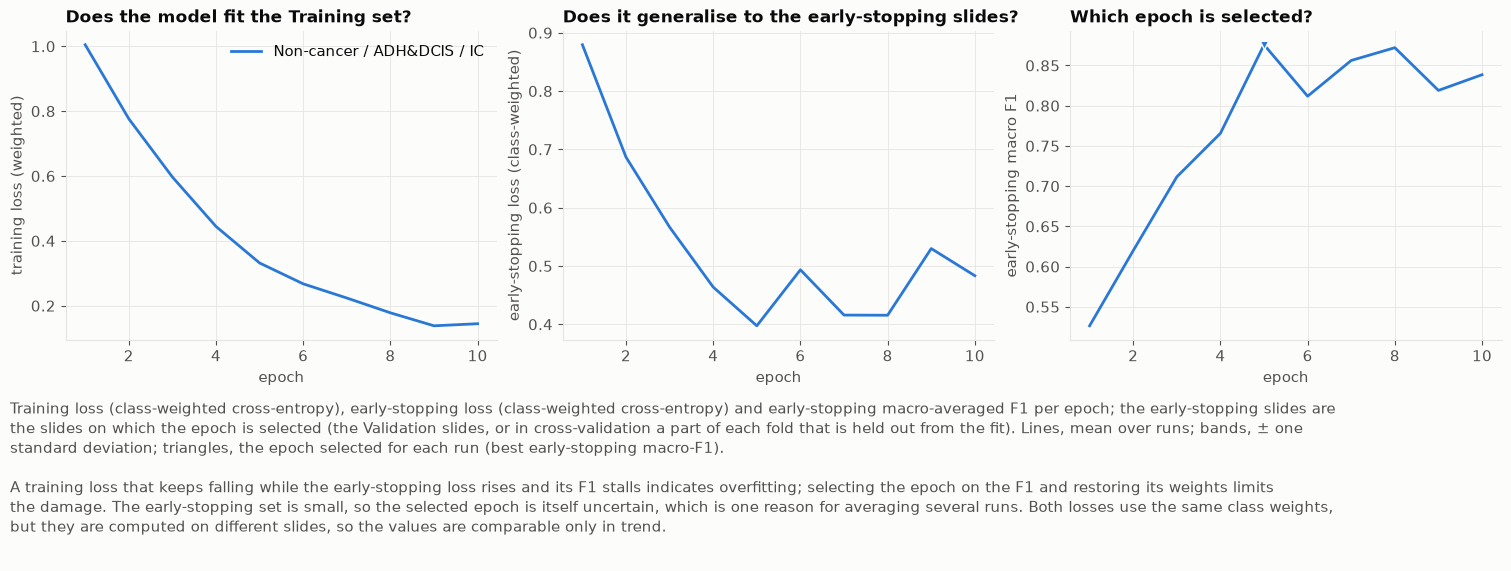

In [29]:
# STEP 1: Train the direct three-class model
t0 = time()
run_ad = train_final(data, table_ad, classes_ad, DEVICE, SEED, WEIGHTING, MODEL_ARGS, TRAIN_ARGS, DROPOUT, TILE_DROPOUT, verbose=False)
print(f"{ADHDCIS}: best epoch {run_ad['best_epoch']} of {run_ad['epochs_run']}, early-stopping macro F1 {run_ad['best']['val_macro_f1']:.3f}, balanced accuracy {run_ad['best']['val_balanced_accuracy']:.3f}  ({time() - t0:.0f} s)")

# STEP 2: Training curves
curves_ad = plot_training_curves({ADHDCIS: [run_ad['history']]}, weighted_val_loss=True)

### 10.3 Evaluation on the Testing set

Confusion matrix, one-vs-rest ROC curves and the measures per class (accuracy, sensitivity, specificity, precision, F1, AUROC) with 95% patient-bootstrap intervals, as in section 5.

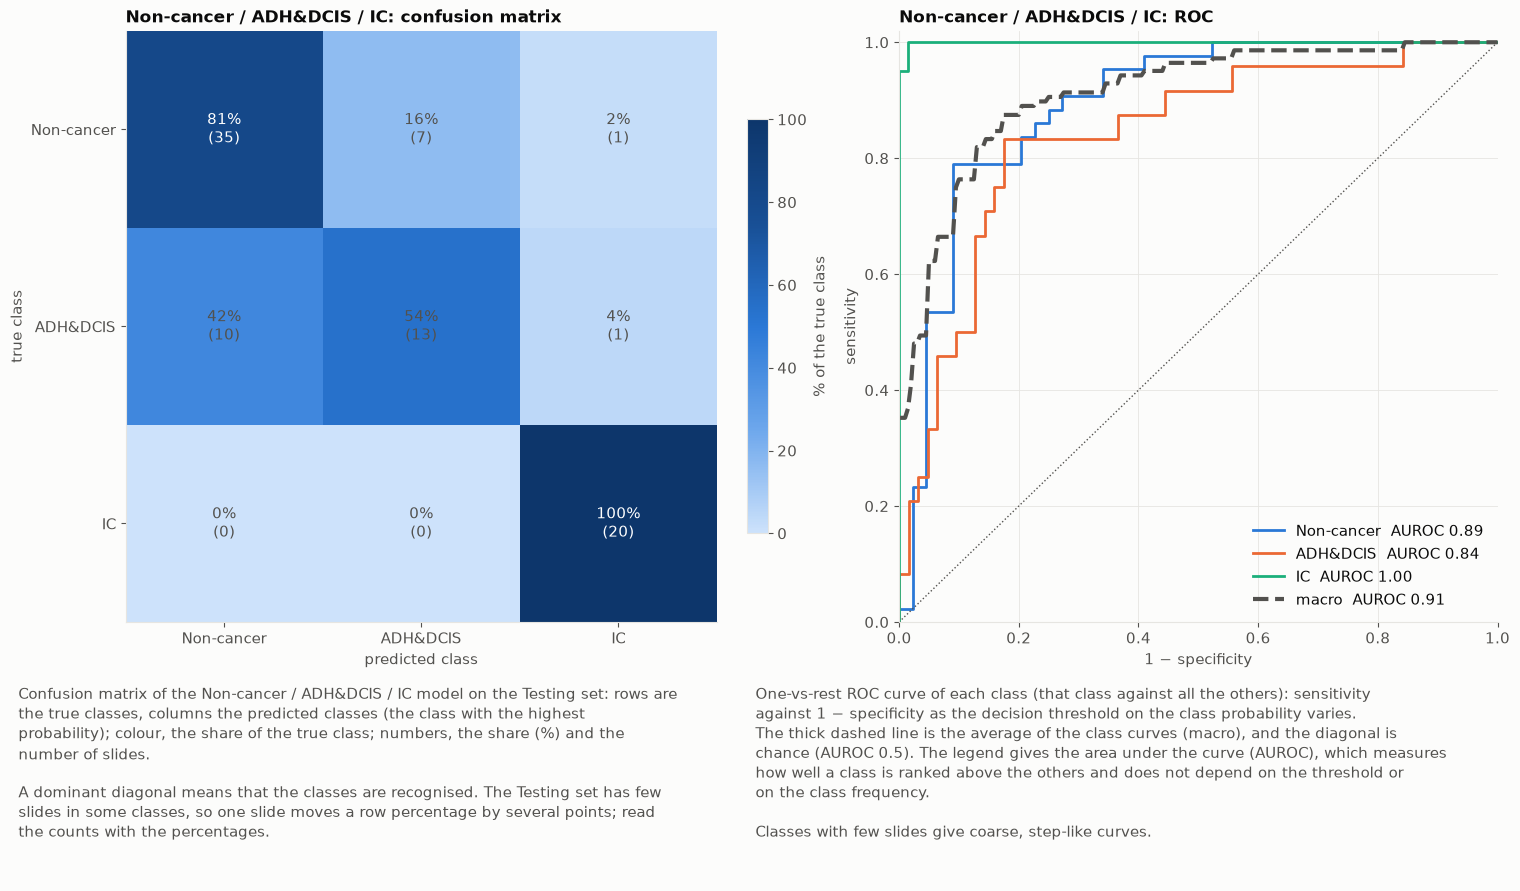

,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"0.793 [0.689, 0.898]","0.814 [0.687, 0.925]","0.773 [0.581, 0.933]","0.778 [0.656, 0.900]","0.795 [0.687, 0.882]","0.894 [0.816, 0.960]"
ADH&DCIS,"0.793 [0.690, 0.892]","0.542 [0.300, 0.800]","0.889 [0.815, 0.957]","0.650 [0.407, 0.862]","0.591 [0.364, 0.800]","0.841 [0.736, 0.933]"
IC,"0.977 [0.944, 1.000]","1.000 [1.000, 1.000]","0.970 [0.927, 1.000]","0.909 [0.750, 1.000]","0.952 [0.857, 1.000]","0.999 [0.995, 1.000]"
macro,"0.782 [0.681, 0.883]","0.785 [0.697, 0.879]","0.877 [0.805, 0.941]","0.779 [0.675, 0.879]","0.780 [0.681, 0.875]","0.911 [0.853, 0.963]"


In [30]:
# STEP 1: Testing predictions and measures
predictions[ADHDCIS] = predict_testing(run_ad, data, table_ad, classes_ad, DEVICE)
class_lists[ADHDCIS] = classes_ad
y_ad, patients_ad, proba_ad = predictions[ADHDCIS]['y'], predictions[ADHDCIS]['patients'], predictions[ADHDCIS]['proba']
evaluation_ad = evaluate_predictions(y_ad, proba_ad, classes_ad)
views[ADHDCIS] = class_views(y_ad, proba_ad, classes_ad)
intervals[ADHDCIS] = bootstrap_views(y_ad, proba_ad, patients_ad, classes_ad, N_BOOT, SEED)

# STEP 2: Figure and table
fig_ad = plot_final_results(ADHDCIS, evaluation_ad['confusion'], y_ad, proba_ad, classes_ad)
display(format_views(views[ADHDCIS], intervals[ADHDCIS]))

### 10.4 Comparison with the direct four-class model

The four-class model of section 7.6.1 is not retrained. Its probabilities of ADH and DCIS are added to give the probability of ADH&DCIS, and its decisions (the class with the highest probability) are mapped to the three classes in the same way; the true labels are those of section 10.1. Both models are then scored on the same Testing slides. The difference (three-class minus merged four-class) comes with a 95% interval from a paired patient bootstrap; an interval that contains zero is not distinguishable from no change at this sample size (87 slides, 31 patients).

In [31]:
# STEP 1: The same Testing slides, in the same order, for both models
assert predictions[ADH4]['test']['slide'].tolist() == predictions[ADHDCIS]['test']['slide'].tolist()

# STEP 2: Merge the outputs of the four-class model into the three classes (columns by name)
FOUR_TO_THREE = {'Non-cancer': 'Non-cancer', 'ADH': 'ADH&DCIS', 'DCIS': 'ADH&DCIS', 'IC': 'IC'}
merge_index = np.array([classes_ad.index(FOUR_TO_THREE[c]) for c in classes_adh4])
proba_merged = np.zeros((len(proba_adh4), len(classes_ad)))
for column, target in enumerate(merge_index):
    proba_merged[:, target] += proba_adh4[:, column]
pred_merged = merge_index[proba_adh4.argmax(1)]
assert np.allclose(proba_merged.sum(1), 1, atol=1e-4)
assert (merge_index[y_adh] == y_ad).all(), 'The merged true labels must be those of section 10.1'

# STEP 3: Measures of the merged four-class model and the macro rows of both
views[ADHDCIS + ' (merged 4-class)'] = class_views(y_ad, proba_merged, classes_ad, pred_merged)
intervals[ADHDCIS + ' (merged 4-class)'] = bootstrap_views(y_ad, proba_merged, patients_ad, classes_ad, N_BOOT, SEED, pred_merged)
print('Direct four-class model, ADH and DCIS merged')
display(format_views(views[ADHDCIS + ' (merged 4-class)'], intervals[ADHDCIS + ' (merged 4-class)']))
print('Macro row')
display(summary_across_sets({'Direct 3-class': views[ADHDCIS], 'Direct 4-class merged': views[ADHDCIS + ' (merged 4-class)']}).round(3))

# STEP 4: Paired patient bootstrap of the difference (three-class minus merged four-class)
differences_ad = paired_bootstrap_views(y_ad, proba_ad, proba_ad.argmax(1), proba_merged, pred_merged, patients_ad, classes_ad, N_BOOT, SEED)
display(format_differences(differences_ad))

Direct four-class model, ADH and DCIS merged


,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"0.816 [0.708, 0.917]","0.884 [0.756, 1.000]","0.750 [0.571, 0.906]","0.776 [0.658, 0.889]","0.826 [0.712, 0.919]","0.895 [0.810, 0.965]"
ADH&DCIS,"0.805 [0.694, 0.907]","0.542 [0.296, 0.786]","0.905 [0.814, 0.983]","0.684 [0.417, 0.938]","0.605 [0.357, 0.810]","0.832 [0.727, 0.928]"
IC,"0.989 [0.959, 1.000]","0.950 [0.833, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.974 [0.909, 1.000]","1.000 [1.000, 1.000]"
macro,"0.805 [0.694, 0.907]","0.792 [0.690, 0.889]","0.885 [0.810, 0.948]","0.820 [0.714, 0.922]","0.802 [0.696, 0.895]","0.909 [0.848, 0.964]"


Macro row


,accuracy,sensitivity,specificity,precision,f1,auroc
Direct 3-class,0.782,0.785,0.877,0.779,0.780,0.911
Direct 4-class merged,0.805,0.792,0.885,0.820,0.802,0.909


,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"-0.023 [-0.080, +0.029]","-0.070 [-0.151, +0.000]","+0.023 [-0.059, +0.094]","+0.002 [-0.061, +0.073]","-0.031 [-0.089, +0.022]","-0.001 [-0.029, +0.031]"
ADH&DCIS,"-0.011 [-0.081, +0.060]","+0.000 [-0.182, +0.160]","-0.016 [-0.083, +0.054]","-0.034 [-0.233, +0.121]","-0.014 [-0.171, +0.129]","+0.009 [-0.040, +0.054]"
IC,"-0.011 [-0.050, +0.026]","+0.050 [+0.000, +0.167]","-0.030 [-0.073, +0.000]","-0.091 [-0.250, +0.000]","-0.022 [-0.120, +0.067]","-0.001 [-0.005, +0.000]"
macro,"-0.023 [-0.086, +0.041]","-0.007 [-0.079, +0.062]","-0.008 [-0.042, +0.024]","-0.041 [-0.134, +0.036]","-0.022 [-0.100, +0.051]","+0.002 [-0.022, +0.026]"


### 10.5 Save

The classifier is written in the format of `save_best_model` to its own subfolder.

In [32]:
# STEP 1: Save the direct three-class model
if SAVE_MODELS:
    path = save_best_model({'clam_mb': [run_ad]}, MODEL_DIR / 'noncancer_adhdcis_ic', {**config, 'label_set': ADHDCIS, 'classes': classes_ad, 'mapping': ADHDCIS_MAPPING})
    print(f'{ADHDCIS}: saved to', path.resolve())
else:
    print('SAVE_MODELS is False: nothing was written.')

Non-cancer / ADH&DCIS / IC: saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/noncancer_adhdcis_ic/classifier_model_2026-11-16_06-24-24.pt
